<a href="https://colab.research.google.com/github/Shaeel-Hasepatil/IT-Workshop3-Exoplanet_Vetting/blob/main/Capstone_Project_v2_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌌 IT Workshop III — Course Project

# 🔭 Explainable Exoplanet Classification and Ranking System with Database-Backed Interactive Dashboard

---

## 👨‍💻 Author

**Name:** Shaeel Santosh Hasepatil

**Roll No.:** 2025BCS0133

**Institute:** IIIT Kottayam

**Course:** IT Workshop III (Python)

**Faculty:** Dr P. Victer Paul

**Notebook Version:** 2.0

**Based on:** my earlier BRICS Astronomy / IDIA Data Analytics capstone — https://github.com/Shaeel-Hasepatil/exoplanet-disposition-classification

---

> *"Data is the language of the universe. Machine Learning helps us understand it."*

---

# 📑 Table of Contents

1. Introduction
2. Problem Definition
3. Dataset Description
4. Prerequisite
5. Import Libraries
6. Loading the Dataset
7. Data Cleaning & Preprocessing
8. Exploratory Data Analysis
9. Feature Engineering
10. Machine Learning Models
11. Model Comparison
12. Model Evaluation
13. Results & Interpretation
14. Leakage-Safe Evaluation (Pipelines & Grouped Cross-Validation)
15. Feature Restoration & Ablation Study
16. Vetting Model & Hyperparameter-Tuned Model Comparison
17. Candidate Ranking
18. Explainability (Permutation Importance & SHAP)
19. Database Integration (SQLite)
20. Interactive Dashboard (Gradio)
21. Conclusion & Future Work
22. References



# 1️⃣ Introduction

---

## 📌 Overview

An exoplanet is a planet that orbits a star other than the Sun. Since the first confirmed detection in the 1990s, over five thousand exoplanets have been identified, primarily through the transit method — detecting the tiny, periodic dip in a star's brightness as a planet passes in front of it. NASA's Kepler space telescope, launched in 2009, was designed specifically to monitor over 150,000 stars simultaneously in search of these transit signals, and remains one of the largest sources of exoplanet detections to date.

Studying exoplanets matters for several reasons: it directly addresses one of the oldest questions in astronomy — how common are planetary systems, and how common are potentially habitable worlds — and it provides a broader context for understanding our own solar system's formation and uniqueness (or lack thereof).

However, not every detected transit signal is a genuine planet. Instrumental noise, stellar variability, and — most commonly — eclipsing binary star systems can all produce transit-like signals that closely mimic a real planet crossing its star. Distinguishing genuine planetary transits from these false positives has traditionally required labor-intensive manual review by teams of astronomers, examining light curves and diagnostic statistics one candidate at a time. As missions like Kepler and its successor TESS have generated tens of thousands of candidate signals, this manual bottleneck has become a genuine limitation on the pace of discovery.

This is where data science contributes directly: rather than manually inspecting each candidate, a classification model can learn the patterns that separate genuine transits from false positives across thousands of previously vetted cases, and apply that learned pattern to new candidates far faster than manual review allows. This project applies exactly that approach, using NASA's own Kepler Objects of Interest (KOI) catalog — a dataset where nearly ten thousand candidate signals have already been vetted and labeled as CONFIRMED, CANDIDATE, or FALSE POSITIVE.

---

## 🌍 Motivation

This project sits at the intersection of a long-standing personal interest in astronomy and the technical skills developed through the BRICS Astronomy / IDIA Data Analytics course. Rather than treating this capstone as a purely academic exercise, the goal was to build something that mirrors real astronomical research practice: NASA's own Kepler pipeline uses automated vetting techniques, including machine learning, to handle exactly this classification problem at scale, and this project follows that same methodological path on a smaller scope.

Beyond the astronomy angle, this project was also an opportunity to work through a complete, realistic data science pipeline — from acquiring live data programmatically, through the often-overlooked but critical challenge of identifying and removing target leakage, to comparing multiple models and interpreting results honestly, including reporting where the model struggles rather than only its successes.

The remainder of this notebook walks through that full pipeline: dataset acquisition and cleaning, exploratory analysis, model training and comparison, and a detailed interpretation of what the results reveal — both about the models built and about the underlying astrophysics they capture.

# 2️⃣ Problem Definition

---

## ❓ Research Question

Can machine learning distinguish genuine transiting exoplanets from false-positive detections in the Kepler Objects of Interest (KOI) dataset, using transit and stellar characteristics, and which features most strongly separate the two classes?

---

## 🎯 Objectives

- Acquire and understand the KOI cumulative dataset from the NASA Exoplanet Archive, including its transit, stellar, and vetting-related features.

- Identify and exclude features that would leak the target label (e.g., pipeline-derived scores and flags), ensuring the model learns from genuine physical/observational signal rather than pre-computed verdicts.

- Handle missing data and class imbalance appropriately, given that CONFIRMED, CANDIDATE, and FALSE POSITIVE classes are not evenly represented in the dataset.

- Train and compare multiple classification models to determine which best distinguishes real exoplanets from false positives.

- Interpret which transit and stellar parameters are most predictive of a genuine detection, and evaluate whether this aligns with known astrophysical reasoning (e.g., transit shape, signal-to-noise, stellar density consistency).

- Evaluate models without leakage, using pipelines and cross-validation grouped by star.

- Test whether restoring astrophysical diagnostic features (centroid offsets, odd-even depth, event statistics) improves detection of false positives.

- Build a CONFIRMED vs FALSE POSITIVE vetting model, tune and compare Random Forest, Gradient Boosting and XGBoost, and use the best one to rank unresolved CANDIDATE signals.

- Explain the model with permutation importance and SHAP, and store predictions in a SQLite database.

- Provide an interactive Gradio dashboard for testing new signals.

---

## Expected Outcomes

A classification model that reliably separates confirmed exoplanets and strong candidates from false positives, evaluated using metrics appropriate for class imbalance (not accuracy alone), along with a feature-importance analysis identifying which observational signals matter most for this vetting task — mirroring, in simplified form, the kind of automated vetting NASA's own pipelines perform.

The final system also ranks the unresolved candidates by planet probability, stores predictions in a SQLite database, and exposes the model through an interactive Gradio dashboard.

# 3️⃣ Dataset Description

---

## 📂 Dataset Source

**Dataset Name:** Kepler Objects of Interest (KOI) — Cumulative Table

**Source:** NASA Exoplanet Archive, operated by Caltech/IPAC under contract with NASA

**URL:** https://exoplanetarchive.ipac.caltech.edu/

**Citation:** "This research has made use of the NASA Exoplanet Archive, which is operated by the California Institute of Technology, under contract with the National Aeronautics and Space Administration under the Exoplanet Exploration Program."

**License:** Publicly available NASA data; cite per Exoplanet Archive's acknowledgment policy.

**Access Method:** Queried programmatically via `astroquery.ipac.nexsci.nasa_exoplanet_archive`, ensuring the notebook is fully reproducible without manual file downloads.

---

## 📊 Dataset Summary

- **Number of observations:** *9564*

- **Number of features (raw):** *155*

- **Target variable:** `koi_disposition` — categorical, three classes: `CONFIRMED`, `CANDIDATE`, `FALSE POSITIVE`

- **Feature types:** Primarily numeric (transit and stellar parameters, signal-to-noise metrics), with some categorical/flag columns

---

## 📋 Feature Description (raw category overview)

| Category | Examples | Notes |
|----------|----------|-------|
| Identifiers | `kepid`, `kepoi_name`, `kepler_name` | Not predictive — will be dropped |
| Transit parameters | `koi_period`, `koi_duration`, `koi_depth`, `koi_prad` | Physical signal characteristics |
| Stellar parameters | `koi_steff`, `koi_slogg`, `koi_srad` | Host star properties |
| Signal quality | `koi_model_snr` | Detection confidence signal |
| Vetting/derived flags | `koi_score`, `koi_pdisposition`, `koi_fpflag_*` | Leakage risk — addressed in Data Cleaning |
| Target | `koi_disposition` | The label being predicted |

---

## Why this dataset?

The KOI cumulative table is the standard benchmark dataset for exoplanet vetting classification, used in published astrophysics literature and NASA's own automated vetting research. It provides genuine observational and stellar features alongside ground-truth dispositions, making it well-suited for a supervised classification task that mirrors a real astronomical problem rather than a toy dataset.

# 4️⃣ Prerequisite

---

The `astroquery` package (NASA archive access), `xgboost` (boosted-tree model), `shap` (model explanations) and `gradio` (web dashboard) are not preinstalled in the Colab environment and must be installed before use.

In [2]:
# Install astroquery for programmatic access to the NASA Exoplanet Archive,
# plus xgboost, shap and gradio used in later sections
!pip install -q astroquery xgboost shap gradio

# 5️⃣ Import Libraries

In [3]:
# ==========================================
# Data Manipulation
# ==========================================

import pandas as pd
import numpy as np

# ==========================================
# Visualization
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# Machine Learning
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix , classification_report
from astroquery.ipac.nexsci.nasa_exoplanet_archive import NasaExoplanetArchive
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
# ==========================================
# Notebook Settings
# ==========================================

pd.set_option("display.max_columns", None)

plt.style.use("ggplot")


# 6️⃣ Loading the Dataset

---

## Load the data

We begin by importing the dataset and performing an initial inspection.

In [4]:
# Query the KOI cumulative table from the NASA Exoplanet Archive
# select="*" retrieves all available columns for initial exploration
koi_table = NasaExoplanetArchive.query_criteria(table="cumulative", select="*")

# Convert from Astropy Table to pandas DataFrame for downstream analysis
df = koi_table.to_pandas()

# Verify dataset dimensions
print(df.shape)

(9564, 155)


In [5]:
# Preview the first few rows of the dataset
df.head()

,kepid,kepoi_name,kepler_name,ra,ra_err,ra_str,dec,dec_err,dec_str,koi_gmag,koi_gmag_err,koi_rmag,koi_rmag_err,koi_imag,koi_imag_err,koi_zmag,koi_zmag_err,koi_jmag,koi_jmag_err,koi_hmag,koi_hmag_err,koi_kmag,koi_kmag_err,koi_kepmag,koi_kepmag_err,koi_delivname,koi_vet_stat,koi_quarters,koi_disposition,koi_pdisposition,koi_count,koi_num_transits,koi_max_sngle_ev,koi_max_mult_ev,koi_bin_oedp_sig,koi_limbdark_mod,koi_ldm_coeff4,koi_ldm_coeff3,koi_ldm_coeff2,koi_ldm_coeff1,koi_trans_mod,koi_model_snr,koi_model_dof,koi_model_chisq,koi_time0bk,koi_time0bk_err1,koi_time0bk_err2,koi_eccen,koi_eccen_err1,koi_eccen_err2,koi_longp,koi_longp_err1,koi_longp_err2,koi_prad,koi_prad_err1,koi_prad_err2,koi_sma,koi_sma_err1,koi_sma_err2,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_ingress,koi_ingress_err1,koi_ingress_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_period,koi_period_err1,koi_period_err2,koi_ror,koi_ror_err1,koi_ror_err2,koi_dor,koi_dor_err1,koi_dor_err2,koi_incl,koi_incl_err1,koi_incl_err2,koi_teq,koi_teq_err1,koi_teq_err2,koi_steff,koi_steff_err1,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_smet,koi_smet_err1,koi_smet_err2,koi_srad,koi_srad_err1,koi_srad_err2,koi_smass,koi_smass_err1,koi_smass_err2,koi_sage,koi_sage_err1,koi_sage_err2,koi_sparprov,koi_fwm_stat_sig,koi_fwm_sra,koi_fwm_sra_err,koi_fwm_sdec,koi_fwm_sdec_err,koi_fwm_srao,koi_fwm_srao_err,koi_fwm_sdeco,koi_fwm_sdeco_err,koi_fwm_prao,koi_fwm_prao_err,koi_fwm_pdeco,koi_fwm_pdeco_err,koi_dicco_mra,koi_dicco_mra_err,koi_dicco_mdec,koi_dicco_mdec_err,koi_dicco_msky,koi_dicco_msky_err,koi_dikco_mra,koi_dikco_mra_err,koi_dikco_mdec,koi_dikco_mdec_err,koi_dikco_msky,koi_dikco_msky_err,koi_comment,koi_vet_date,koi_tce_plnt_num,koi_tce_delivname,koi_datalink_dvs,koi_disp_prov,koi_parm_prov,koi_time0,koi_time0_err1,koi_time0_err2,koi_datalink_dvr,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_insol,koi_insol_err1,koi_insol_err2,koi_srho,koi_srho_err1,koi_srho_err2,koi_fittype,koi_score,sky_coord.ra,sky_coord.dec
0,10797460,K00752.01,Kepler-227 b,291.93423,0.0,19h27m44.22s,48.141651,0.0,+48d08m29.9s,15.890,NaN,15.270,NaN,15.114,NaN,15.006,NaN,14.082,0.025,13.751,0.030,13.648,0.054,15.347,NaN,cumulative,Done,11111111111111111000000000000000,CONFIRMED,CANDIDATE,2,142,5.135849,28.470820,0.6864,Claret (2011 A&A 529 75) ATLAS LS,0.0,0.0,0.2291,0.4603,Mandel and Agol (2002 ApJ 580 171),35.8,NaN,NaN,170.538750,0.002160,-0.002160,0.0,NaN,NaN,NaN,NaN,NaN,2.26,0.26,-0.15,0.0853,NaN,NaN,0.146,0.318,-0.146,2.95750,0.08190,-0.08190,NaN,NaN,NaN,615.8,19.5,-19.5,9.488036,2.775000e-05,-2.775000e-05,0.022344,0.000832,-0.000528,24.810,2.600,-2.600,89.66,NaN,NaN,793.0,NaN,NaN,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.14,0.15,-0.15,0.927,0.105,-0.061,0.919,0.052,-0.046,NaN,NaN,NaN,q1_q17_dr25_stellar,0.002,19.462294,1.400000e-05,48.14191,0.000130,0.430,0.510,0.940,0.480,-0.00020,0.00032,-0.00055,0.00031,-0.010,0.130,0.200,0.160,0.200,0.170,0.080,0.130,0.310,0.170,0.320,0.160,NO_COMMENT,2018-08-16 00:00:00,1,q1_q17_dr25_tce,010/010797/010797460/dv/kplr010797460-001-2016...,q1_q17_dr25_sup_koi,q1_q17_dr25_koi,2455003.539,0.002160,-0.002160,010/010797/010797460/dv/kplr010797460-20160209...,0,0,0,0,93.59,29.45,-16.65,3.20796,0.33173,-1.09986,LS+MCMC,1.000,291.93423,48.141651
1,10797460,K00752.02,Kepler-227 c,291.93423,0.0,19h27m44.22s,48.141651,0.0,+48d08m29.9s,15.890,NaN,15.270,NaN,15.114,NaN,15.006,NaN,14.082,0.025,13.751,0.030,13.648,0.054,15.347,NaN,cumulative,Done,11111111111111111000000000000000,CONFIRMED,CANDIDATE,2,25,7.027669,20.109507,0.0023,Claret (2011 A&A 529 75) ATLAS LS,0.0,0.0,0.2291,0.4603,Mandel and Agol (2002 ApJ 580 171),25.8,NaN,NaN,162.513840,0.003520,-0.003520,0.0,NaN,NaN,NaN,NaN,NaN,2.83,0.32,-0.19,0.2734,NaN,NaN,0.586,0.059,-0.443,4.50700,0.11600,-0.11600,NaN,NaN,NaN,874.8,35.5,-35.5,54.418383,2.479000e-04,-2.479000e-04,0.027954,0.009078,-0.001347,77.900,28.400,-28.400,89.57,NaN,NaN,443.0,NaN,NaN,5455.

In [6]:
# Inspect column data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Columns: 155 entries, kepid to sky_coord.dec
dtypes: float64(127), int32(8), object(20)
memory usage: 11.0+ MB


In [7]:
# Summary statistics for numeric columns
df.describe()

,kepid,ra,ra_err,dec,dec_err,koi_gmag,koi_gmag_err,koi_rmag,koi_rmag_err,koi_imag,koi_imag_err,koi_zmag,koi_zmag_err,koi_jmag,koi_jmag_err,koi_hmag,koi_hmag_err,koi_kmag,koi_kmag_err,koi_kepmag,koi_kepmag_err,koi_count,koi_num_transits,koi_max_sngle_ev,koi_max_mult_ev,koi_bin_oedp_sig,koi_ldm_coeff4,koi_ldm_coeff3,koi_ldm_coeff2,koi_ldm_coeff1,koi_model_snr,koi_model_dof,koi_model_chisq,koi_time0bk,koi_time0bk_err1,koi_time0bk_err2,koi_eccen,koi_eccen_err1,koi_eccen_err2,koi_longp,koi_longp_err1,koi_longp_err2,koi_prad,koi_prad_err1,koi_prad_err2,koi_sma,koi_sma_err1,koi_sma_err2,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_ingress,koi_ingress_err1,koi_ingress_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_period,koi_period_err1,koi_period_err2,koi_ror,koi_ror_err1,koi_ror_err2,koi_dor,koi_dor_err1,koi_dor_err2,koi_incl,koi_incl_err1,koi_incl_err2,koi_teq,koi_teq_err1,koi_teq_err2,koi_steff,koi_steff_err1,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_smet,koi_smet_err1,koi_smet_err2,koi_srad,koi_srad_err1,koi_srad_err2,koi_smass,koi_smass_err1,koi_smass_err2,koi_sage,koi_sage_err1,koi_sage_err2,koi_fwm_stat_sig,koi_fwm_sra,koi_fwm_sra_err,koi_fwm_sdec,koi_fwm_sdec_err,koi_fwm_srao,koi_fwm_srao_err,koi_fwm_sdeco,koi_fwm_sdeco_err,koi_fwm_prao,koi_fwm_prao_err,koi_fwm_pdeco,koi_fwm_pdeco_err,koi_dicco_mra,koi_dicco_mra_err,koi_dicco_mdec,koi_dicco_mdec_err,koi_dicco_msky,koi_dicco_msky_err,koi_dikco_mra,koi_dikco_mra_err,koi_dikco_mdec,koi_dikco_mdec_err,koi_dikco_msky,koi_dikco_msky_err,koi_tce_plnt_num,koi_time0,koi_time0_err1,koi_time0_err2,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_insol,koi_insol_err1,koi_insol_err2,koi_srho,koi_srho_err1,koi_srho_err2,koi_score,sky_coord.ra,sky_coord.dec
count,9.564000e+03,9564.000000,9564.0,9564.000000,9564.0,9523.000000,0.0,9555.000000,0.0,9410.000000,0.0,8951.000000,0.0,9539.000000,9492.000000,9539.000000,9467.000000,9539.00000,9371.000000,9563.000000,0.0,9564.000000,9564.000000,8422.000000,8422.000000,8054.000000,9201.0,9201.0,9201.000000,9201.000000,9201.000000,0.0,0.0,9564.000000,9110.000000,9110.000000,9201.0,0.0,0.0,0.0,0.0,0.0,9201.000000,9201.000000,9201.000000,9201.000000,0.0,0.0,9201.000000,9110.000000,9110.000000,9564.000000,9110.000000,9110.000000,0.0,0.0,0.0,9.201000e+03,9110.000000,9110.000000,9564.000000,9110.000000,9110.000000,9201.000000,9201.000000,9201.000000,9201.000000,9110.000000,9110.000000,9200.000000,0.0,0.0,9201.000000,0.0,0.0,9201.000000,9096.000000,9081.000000,9201.000000,9096.000000,9096.000000,9178.000000,9177.000000,9177.000000,9201.000000,9096.000000,9096.000000,9201.000000,9096.000000,9096.000000,0.0,0.0,0.0,8488.000000,9058.000000,9.058000e+03,9058.000000,9.058000e+03,9109.000000,9109.000000,9109.000000,9109.000000,8734.000000,8734.000000,8747.000000,8747.000000,8965.000000,8965.000000,8965.000000,8965.000000,8965.000000,8965.000000,8994.000000,8994.000000,8994.000000,8994.000000,8994.000000,8994.000000,9564.000000,9.564000e+03,9110.000000,9110.000000,9564.000000,9564.000000,9564.000000,9564.000000,9.243000e+03,9.243000e+03,9.243000e+03,9243.000000,9243.000000,9243.000000,8054.000000,9564.000000,9564.000000
mean,7.690628e+06,292.060163,0.0,43.810433,0.0,14.830501,NaN,14.221565,NaN,14.075138,NaN,13.991724,NaN,12.993311,0.026168,12.620604,0.028099,12.54341,0.033455,14.264606,NaN,1.406315,339.034609,176.846052,1025.664672,0.409500,0.0,0.0,0.254439,0.407617,259.895001,NaN,NaN,166.183251,0.009933,-0.009933,0.0,NaN,NaN,NaN,NaN,NaN,102.891778,17.657684,-33.023314,0.223989,NaN,NaN,0.735105,1.959861,-0.332557,5.621606,0.339942,-0.339942,NaN,NaN,NaN,2.379134e+04,123.197563,-123.197563,75.671358,0.002148,-0.002148,0.283646,1.781782,-0.100652,76.736333,23.678551,-23.678551,82.469147,NaN,NaN,1085.385828,NaN,NaN,5706.823280,144.635554,-162.265059,4.310157,0.120738,-0.143161,-0.124431,0.228716,-0.252033,1.728712,0.362292,-0.394806,1.023706,0.122801,-0.138824,NaN,NaN,NaN,0.150994,19.47135

In [8]:
# Class distribution of the target variable
df['koi_disposition'].value_counts()

,count
koi_disposition,
FALSE POSITIVE,4839
CONFIRMED,2748
CANDIDATE,1977


In [9]:
# Missing value count per column, sorted in descending order
pd.set_option("display.max_rows", None)
df.isnull().sum().sort_values(ascending=False)

,0
koi_gmag_err,9564
koi_imag_err,9564
koi_rmag_err,9564
koi_kepmag_err,9564
koi_zmag_err,9564
koi_eccen_err2,9564
koi_eccen_err1,9564
koi_sma_err2,9564
koi_sage,9564
koi_sage_err1,9564


# 7️⃣ Data Cleaning & Preprocessing

---

This section prepares the dataset for modeling. The following steps are performed:

✅ Removal of fully empty columns

✅ Removal of leakage, metadata, and identifier columns

✅ Holding back diagnostic columns that are re-introduced and tested in Section 15

✅ Missing value imputation for retained features

✅ Verification of the cleaned dataset

In [10]:
# Columns with 100% missing values (no usable data)
fully_empty_cols = [
    'koi_gmag_err', 'koi_imag_err', 'koi_rmag_err', 'koi_kepmag_err', 'koi_zmag_err',
    'koi_eccen_err1', 'koi_eccen_err2', 'koi_sma_err1', 'koi_sma_err2',
    'koi_sage', 'koi_sage_err1', 'koi_sage_err2',
    'koi_ingress', 'koi_ingress_err1', 'koi_ingress_err2',
    'koi_incl_err1', 'koi_incl_err2', 'koi_teq_err1', 'koi_teq_err2',
    'koi_longp', 'koi_longp_err1', 'koi_longp_err2',
    'koi_model_chisq', 'koi_model_dof'
]

# Columns that leak the target label, describe vetting metadata, or are non-predictive identifiers
leakage_metadata_id_cols = [
    'koi_score', 'koi_pdisposition',
    'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec',
    'koi_vet_stat', 'koi_vet_date', 'koi_disp_prov', 'koi_parm_prov', 'koi_sparprov',
    'koi_comment', 'koi_delivname', 'koi_tce_delivname',
    'koi_datalink_dvs', 'koi_datalink_dvr', 'koi_trans_mod', 'koi_limbdark_mod', 'koi_fittype',
    'kepid', 'kepoi_name', 'kepler_name',
    'ra', 'dec', 'ra_str', 'dec_str', 'ra_err', 'dec_err',
    'sky_coord.ra', 'sky_coord.dec'
]

df_clean = df.drop(columns=fully_empty_cols + leakage_metadata_id_cols)
print(df_clean.shape)

(9564, 101)


Columns such as `koi_pdisposition`, `koi_score`, and the `koi_fpflag_*` flags are excluded because they are outputs of NASA's own automated vetting pipeline — the same process that generates the `koi_disposition` target label. Including them would allow the model to effectively look up the answer rather than learn to distinguish genuine transits from false positives using independent physical and observational features. Metadata columns (e.g., `koi_vet_stat`, `koi_disp_prov`) and identifier/location columns (e.g., `kepid`, `ra`, `dec`) are excluded as they describe processing history or sky position rather than physical signal characteristics relevant to classification.

In [11]:
# Columns held back from the initial feature set (re-introduced and tested in Section 15):
# photometric magnitudes, centroid offset diagnostics, transit timing bookkeeping,
# and additional transit statistics not used in this analysis
out_of_scope_cols = [
    'koi_gmag', 'koi_rmag', 'koi_imag', 'koi_zmag', 'koi_jmag', 'koi_hmag',
    'koi_kmag', 'koi_kepmag', 'koi_jmag_err', 'koi_hmag_err', 'koi_kmag_err',
    'koi_fwm_sra', 'koi_fwm_sra_err', 'koi_fwm_sdec', 'koi_fwm_sdec_err',
    'koi_fwm_srao', 'koi_fwm_srao_err', 'koi_fwm_sdeco', 'koi_fwm_sdeco_err',
    'koi_fwm_prao', 'koi_fwm_prao_err', 'koi_fwm_pdeco', 'koi_fwm_pdeco_err',
    'koi_fwm_stat_sig',
    'koi_dicco_mra', 'koi_dicco_mra_err', 'koi_dicco_mdec', 'koi_dicco_mdec_err',
    'koi_dicco_msky', 'koi_dicco_msky_err',
    'koi_dikco_mra', 'koi_dikco_mra_err', 'koi_dikco_mdec', 'koi_dikco_mdec_err',
    'koi_dikco_msky', 'koi_dikco_msky_err',
    'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2',
    'koi_time0', 'koi_time0_err1', 'koi_time0_err2',
    'koi_max_mult_ev', 'koi_max_sngle_ev', 'koi_bin_oedp_sig',
    'koi_quarters', 'koi_tce_plnt_num', 'koi_count', 'koi_num_transits'
]

df_clean = df_clean.drop(columns=out_of_scope_cols)
print(df_clean.shape)

(9564, 52)


Centroid offset diagnostics (`koi_fwm_*`, `koi_dicco_*`, `koi_dikco_*`) and odd-even transit depth significance (`koi_bin_oedp_sig`) are held back from the initial feature set. These are genuine astrophysical indicators used to detect background eclipsing binaries (a common source of false positives). Section 15 adds them back and measures how much they improve the model.

In [12]:
# Remaining features have partial missingness (under 5% of rows)
# Median imputation is used to preserve these rows while remaining robust to outliers
numeric_cols = df_clean.select_dtypes(include=['float64', 'int32']).columns
numeric_cols = numeric_cols.drop('koi_disposition', errors='ignore')

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

In [13]:
# Confirm no missing values remain in the retained feature set
df_clean.isnull().sum().sum()

np.int64(0)

In [14]:
# Final shape of the cleaned dataset
print(df_clean.shape)
df_clean.head()

(9564, 52)


,koi_disposition,koi_ldm_coeff4,koi_ldm_coeff3,koi_ldm_coeff2,koi_ldm_coeff1,koi_model_snr,koi_eccen,koi_prad,koi_prad_err1,koi_prad_err2,koi_sma,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_period,koi_period_err1,koi_period_err2,koi_ror,koi_ror_err1,koi_ror_err2,koi_dor,koi_dor_err1,koi_dor_err2,koi_incl,koi_teq,koi_steff,koi_steff_err1,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_smet,koi_smet_err1,koi_smet_err2,koi_srad,koi_srad_err1,koi_srad_err2,koi_smass,koi_smass_err1,koi_smass_err2,koi_insol,koi_insol_err1,koi_insol_err2,koi_srho,koi_srho_err1,koi_srho_err2
0,CONFIRMED,0.0,0.0,0.2291,0.4603,35.8,0.0,2.26,0.26,-0.15,0.0853,0.146,0.318,-0.146,2.95750,0.08190,-0.08190,615.8,19.5,-19.5,9.488036,2.775000e-05,-2.775000e-05,0.022344,0.000832,-0.000528,24.810,2.600,-2.600,89.66,793.0,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.14,0.15,-0.15,0.927,0.105,-0.061,0.919,0.052,-0.046,93.59,29.45,-16.65,3.20796,0.33173,-1.09986
1,CONFIRMED,0.0,0.0,0.2291,0.4603,25.8,0.0,2.83,0.32,-0.19,0.2734,0.586,0.059,-0.443,4.50700,0.11600,-0.11600,874.8,35.5,-35.5,54.418383,2.479000e-04,-2.479000e-04,0.027954,0.009078,-0.001347,77.900,28.400,-28.400,89.57,443.0,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.14,0.15,-0.15,0.927,0.105,-0.061,0.919,0.052,-0.046,9.11,2.87,-1.62,3.02368,2.20489,-2.49638
2,CANDIDATE,0.0,0.0,0.2711,0.3858,76.3,0.0,14.60,3.92,-1.31,0.1419,0.969,5.126,-0.077,1.78220,0.03410,-0.03410,10829.0,171.0,-171.0,19.899140,1.494000e-05,-1.494000e-05,0.154046,5.034292,-0.042179,53.500,25.700,-25.700,88.96,638.0,5853.0,158.0,-176.0,4.544,0.044,-0.176,-0.18,0.30,-0.30,0.868,0.233,-0.078,0.961,0.110,-0.121,39.30,31.04,-10.49,7.29555,35.03293,-2.75453
3,FALSE POSITIVE,0.0,0.0,0.2865,0.3556,505.6,0.0,33.46,8.50,-2.83,0.0267,1.276,0.115,-0.092,2.40641,0.00537,-0.00537,8079.2,12.8,-12.8,1.736952,2.630000e-07,-2.630000e-07,0.387394,0.109232,-0.084950,3.278,0.136,-0.136,67.09,1395.0,5805.0,157.0,-174.0,4.564,0.053,-0.168,-0.52,0.30,-0.30,0.791,0.201,-0.067,0.836,0.093,-0.077,891.96,668.95,-230.35,0.22080,0.00917,-0.01837
4,CONFIRMED,0.0,0.0,0.2844,0.3661,40.9,0.0,2.75,0.88,-0.35,0.0374,0.701,0.235,-0.478,1.65450,0.04200,-0.04200,603.3,16.9,-16.9,2.525592,3.761000e-06,-3.761000e-06,0.024064,0.003751,-0.001522,8.750,4.000,-4.000,85.41,1406.0,6031.0,169.0,-211.0,4.438,0.070,-0.210,0.07,0.25,-0.30,1.046,0.334,-0.133,1.095,0.151,-0.136,926.16,874.33,-314.24,1.98635,2.71141,-1.74541


# 8️⃣ Exploratory Data Analysis

---

The objective of this section is to understand the characteristics of the dataset before modeling.

Every visualization will be followed by an interpretation.

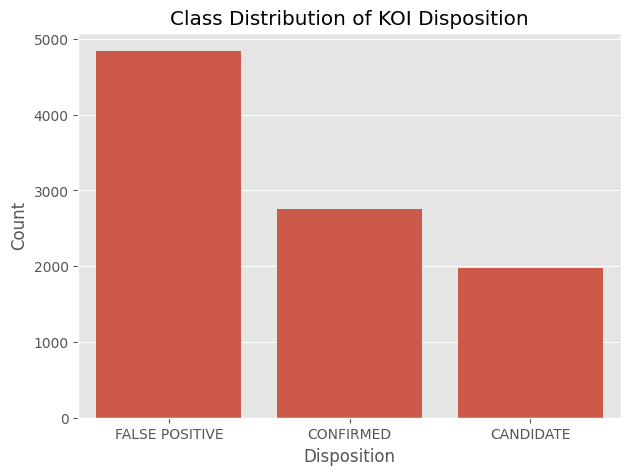

In [15]:
# Visualize the distribution of the target variable across its three classes
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x='koi_disposition', order=df_clean['koi_disposition'].value_counts().index)
plt.title('Class Distribution of KOI Disposition')
plt.xlabel('Disposition')
plt.ylabel('Count')
plt.show()

**Interpretation**: The dataset shows moderate class imbalance — FALSE POSITIVE (4839, ~50.6%) is roughly 2.4× larger than CANDIDATE (1978, ~20.7%), with CONFIRMED (2747, ~28.7%) in between. This imbalance is not severe enough to require aggressive resampling, but it does mean accuracy alone would be a misleading evaluation metric — a model predicting FALSE POSITIVE for every row would already reach ~50% accuracy without learning anything. Per-class precision, recall, and F1 (via classification_report) will be used instead.

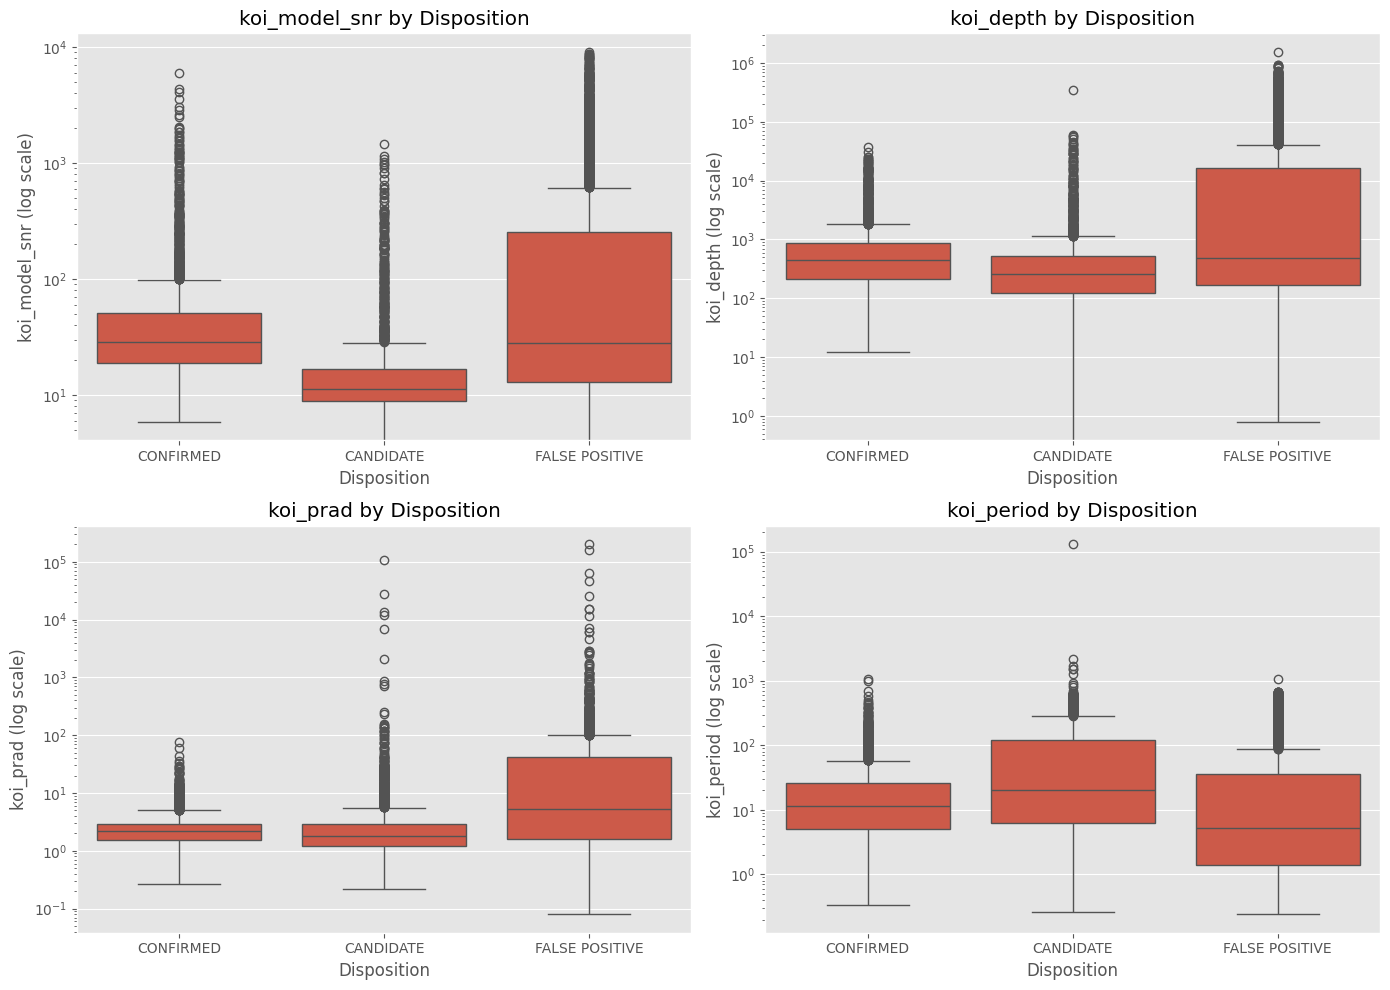

In [16]:
# Compare distributions of key physical features across disposition classes
key_features = ['koi_model_snr', 'koi_depth', 'koi_prad', 'koi_period']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(key_features):
    sns.boxplot(data=df_clean, x='koi_disposition', y=feature, ax=axes[i])
    axes[i].set_yscale('log')
    axes[i].set_title(f'{feature} by Disposition')
    axes[i].set_xlabel('Disposition')
    axes[i].set_ylabel(f'{feature} (log scale)')

plt.tight_layout()
plt.show()

**Interpretation**: A log scale is used on the y-axis since these physical quantities span several orders of magnitude. koi_model_snr (signal-to-noise ratio) shows a visible separation — FALSE POSITIVE entries tend to include a long tail of very high SNR values, consistent with strong but non-planetary signals such as eclipsing binaries. koi_depth shows a similar pattern: false positives include some extremely deep "transits," physically implausible for a genuine planet relative to its host star, again pointing to eclipsing binary contamination. koi_prad (planet radius) and koi_period show more overlap across classes, suggesting these alone are weaker discriminators and the model will likely need to combine several features rather than rely on any single one.

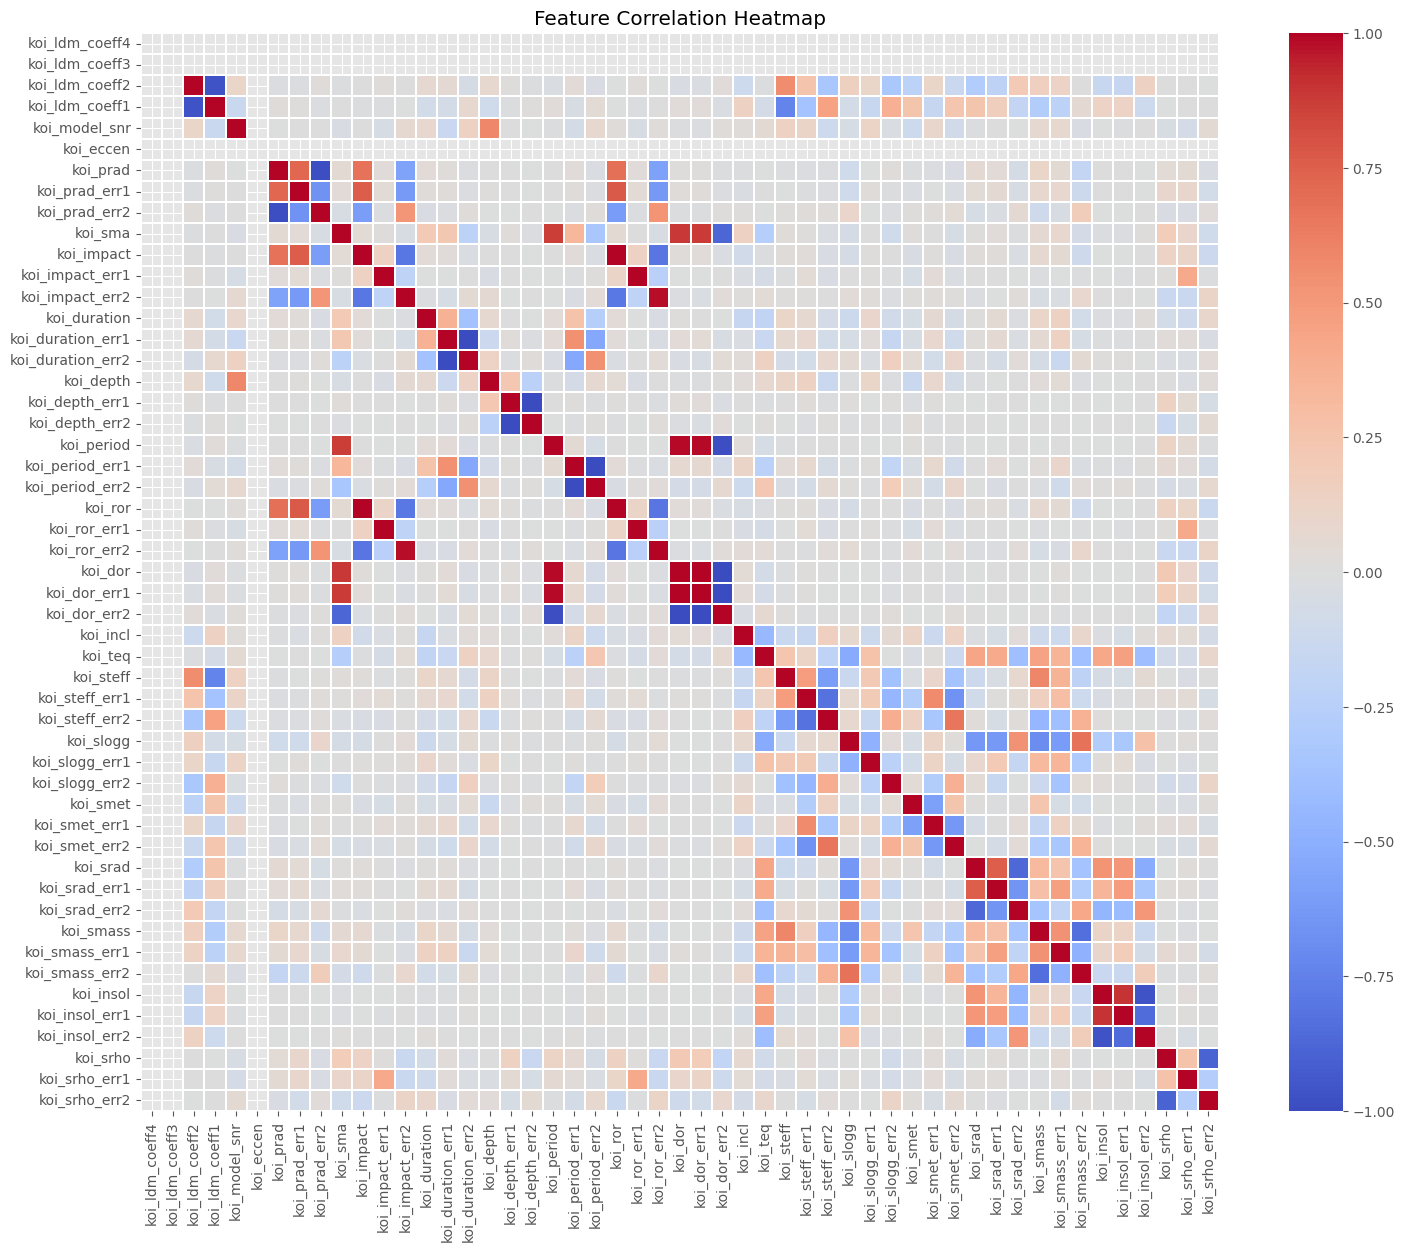

In [17]:
# Correlation among numeric features to identify redundancy and relationships
plt.figure(figsize=(18, 14))
numeric_df = df_clean.select_dtypes(include=['float64', 'int32', 'int64'])
corr = numeric_df.corr()
sns.heatmap(corr, cmap='coolwarm', center=0, linewidths=0.3, square=True)
plt.title('Feature Correlation Heatmap')
plt.show()

**Interpretation**: As expected, each measurement's error-bar pair (e.g., koi_period_err1 and koi_period_err2) is strongly correlated, since they represent the upper and lower uncertainty bounds on the same value. Several stellar parameters (koi_srad, koi_smass, koi_slogg) also show correlation with each other, which is physically expected since these are related properties of the same host star. No pair reaches a level that would suggest redundant, duplicate information beyond what's already expected from paired error bars, so no additional features are dropped at this stage.

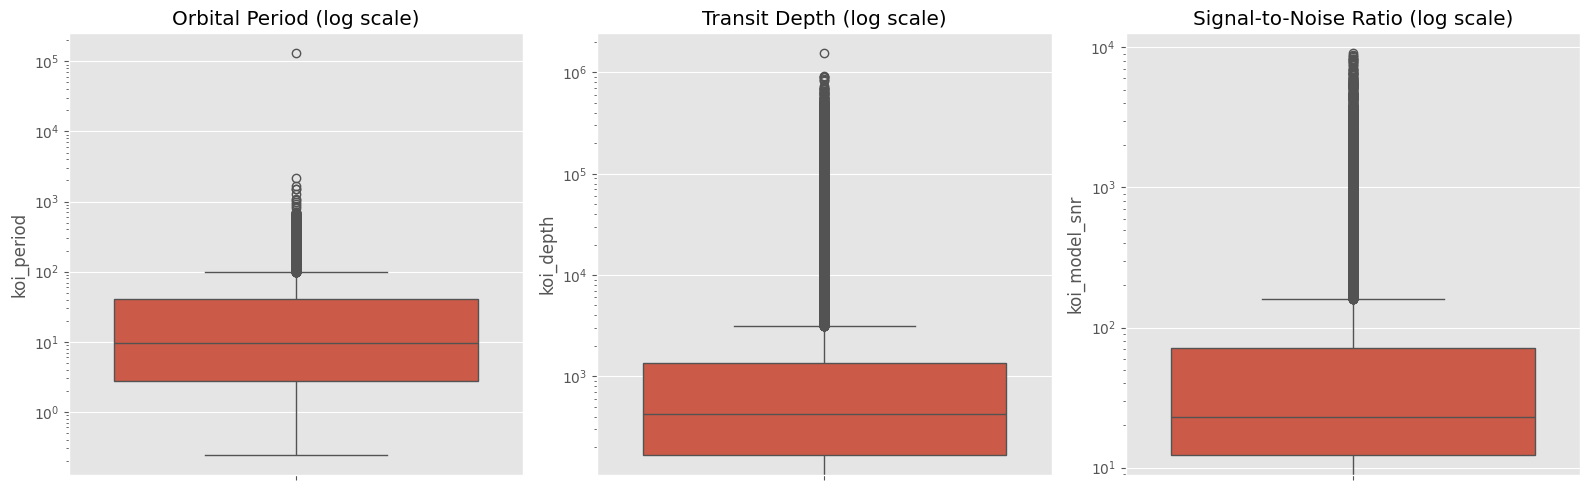

In [18]:
# Check for extreme outliers in key physical features
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df_clean, y='koi_period', ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Orbital Period (log scale)')

sns.boxplot(data=df_clean, y='koi_depth', ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Transit Depth (log scale)')

sns.boxplot(data=df_clean, y='koi_model_snr', ax=axes[2])
axes[2].set_yscale('log')
axes[2].set_title('Signal-to-Noise Ratio (log scale)')

plt.tight_layout()
plt.show()

**Interpretation**: All three features show a wide spread with a number of high-end outliers, but these are not treated as data errors — in this domain, extreme values are often astrophysically real (a very deep, high-SNR "transit" is often the eclipsing binary signature discussed above, not a mistake). No outlier removal is performed at this stage. Tree-based models (Random Forest, Gradient Boosting) are also naturally robust to outliers, so this is left as-is for modeling.

# 📌 Key Insights from EDA

- The dataset is moderately imbalanced (FALSE POSITIVE ~51%, CONFIRMED ~29%, CANDIDATE ~21%), requiring evaluation metrics beyond accuracy.

- Signal-to-noise ratio and transit depth show visible separation between FALSE POSITIVE and the other two classes, consistent with eclipsing binary contamination in the false-positive population.

- Planet radius and orbital period alone show weaker class separation, suggesting the model will rely on a combination of features rather than any single strong predictor.

- No features were removed due to correlation; expected correlation exists only within measurement/error-bar pairs and among related stellar parameters.

- Outliers in physical features are retained, as extreme values are often genuine astrophysical signatures rather than data errors.

# 9️⃣ Feature Engineering

---

This section prepares the cleaned dataset for modeling:

✅ Encoding the target variable

✅ Separating features and target

✅ Train/test split (stratified)

✅ Feature scaling

In [19]:
# Encode the target variable into numeric labels for modeling
# LabelEncoder sorts alphabetically: CANDIDATE = 0, CONFIRMED = 1, FALSE POSITIVE = 2
# (order does not affect model performance)
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df_clean['koi_disposition_encoded'] = label_encoder.fit_transform(df_clean['koi_disposition'])

# Confirm the mapping between original labels and encoded values
dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))

{'CANDIDATE': np.int64(0),
 'CONFIRMED': np.int64(1),
 'FALSE POSITIVE': np.int64(2)}

Class labels are encoded numerically as follows: CANDIDATE = 0, CONFIRMED = 1, FALSE POSITIVE = 2 (alphabetical order assigned by `LabelEncoder`). This encoding is arbitrary and carries no ordinal meaning — the model does not treat CANDIDATE as "between" CONFIRMED and FALSE POSITIVE numerically. This is appropriate for the classifiers used here, which output class probabilities rather than treat labels as continuous values.

In [20]:
# Separate features (X) and target (y)
X = df_clean.drop(columns=['koi_disposition', 'koi_disposition_encoded'])
y = df_clean['koi_disposition_encoded']

print(X.shape, y.shape)

(9564, 51) (9564,)


In [21]:
# Split into training and test sets
# stratify=y ensures all three classes are proportionally represented in both sets,
# which matters given the class imbalance identified during EDA
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(7651, 51) (1913, 51)


The split uses `stratify=y` to ensure all three classes are proportionally represented in both the training and test sets. This is particularly important given the class imbalance identified during EDA — CANDIDATE is already the smallest class at roughly 21% of the data, and a non-stratified random split risks further under-representing it in the test set, which would make evaluation on that class unreliable.

In [22]:
# Scale features for models that are sensitive to feature magnitude (Logistic Regression)
# Tree-based models (Random Forest, Gradient Boosting) do not require scaling,
# but a single scaled version is kept for consistency and reused where needed
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

The scaler is fit only on the training data (`fit_transform`) and then applied to the test data using the already-fitted parameters (`transform` only). Fitting the scaler on the full dataset before splitting would leak information about the test set's distribution into training, undermining the validity of the evaluation.

# 🔟 Machine Learning Models

---

Three classification models are trained and compared:

- **Logistic Regression** — a linear baseline, using scaled features
- **Random Forest** — a non-linear ensemble of decision trees, using unscaled features
- **Gradient Boosting** — a sequentially-corrected tree ensemble, using unscaled features

Each model is trained on the same underlying data split to ensure a fair comparison.

### Logistic Regression

In [23]:
# Logistic Regression baseline — linear model, requires scaled features
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred_log_reg = log_reg.predict(X_test_scaled)

**Why this model**: Logistic Regression establishes a simple, interpretable baseline. Its coefficients directly show the direction and relative strength of each feature's influence on the predicted class, giving an initial linear view of the problem before more complex models are introduced.

### Random Forest

In [24]:
# Random Forest — ensemble of decision trees, does not require feature scaling
rand_forest = RandomForestClassifier(n_estimators=200, random_state=42)
rand_forest.fit(X_train, y_train)

y_pred_rf = rand_forest.predict(X_test)

**Why this model**: Random Forest can capture non-linear relationships between features and the target that Logistic Regression cannot. It also provides feature importance scores, useful for identifying which transit and stellar parameters most strongly separate genuine planets from false positives.

### Gradient Boosting

In [25]:
# Gradient Boosting — sequential ensemble, does not require feature scaling
grad_boost = GradientBoostingClassifier(random_state=42)
grad_boost.fit(X_train, y_train)

y_pred_gb = grad_boost.predict(X_test)

**Why this model**: Gradient Boosting builds trees sequentially, with each new tree correcting errors made by the previous ones. It often achieves stronger performance than Random Forest on structured/tabular data of this kind, at the cost of longer training time.

# 1️⃣1️⃣ Model Comparison

---

Each model's predictions on the test set are evaluated using accuracy, precision, recall, and F1-score. Given the class imbalance identified during EDA, macro-averaged precision/recall/F1 are used so that performance on the smaller CANDIDATE class is not overshadowed by the larger FALSE POSITIVE class.

In [26]:
# Import additional metric functions to extract individual scores for the comparison table
from sklearn.metrics import precision_score, recall_score, f1_score

def get_metrics(y_true, y_pred, model_name):
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (macro)': precision_score(y_true, y_pred, average='macro'),
        'Recall (macro)': recall_score(y_true, y_pred, average='macro'),
        'F1 (macro)': f1_score(y_true, y_pred, average='macro')
    }

results = [
    get_metrics(y_test, y_pred_log_reg, 'Logistic Regression'),
    get_metrics(y_test, y_pred_rf, 'Random Forest'),
    get_metrics(y_test, y_pred_gb, 'Gradient Boosting')
]

comparison_df = pd.DataFrame(results)
comparison_df

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Logistic Regression,0.751699,0.700694,0.682313,0.678256
1,Random Forest,0.800314,0.768244,0.754894,0.760305
2,Gradient Boosting,0.801882,0.770558,0.764039,0.766652


Macro-averaged precision, recall, and F1 are used rather than accuracy alone, since the earlier EDA identified moderate class imbalance (FALSE POSITIVE ~51%, CONFIRMED ~29%, CANDIDATE ~21%). Macro-averaging computes each metric separately per class and takes an unweighted average, ensuring the smallest class (CANDIDATE) is not overshadowed by the largest. This directly addresses the risk that a model could achieve a high accuracy score simply by favoring the majority class while performing poorly on minority classes.

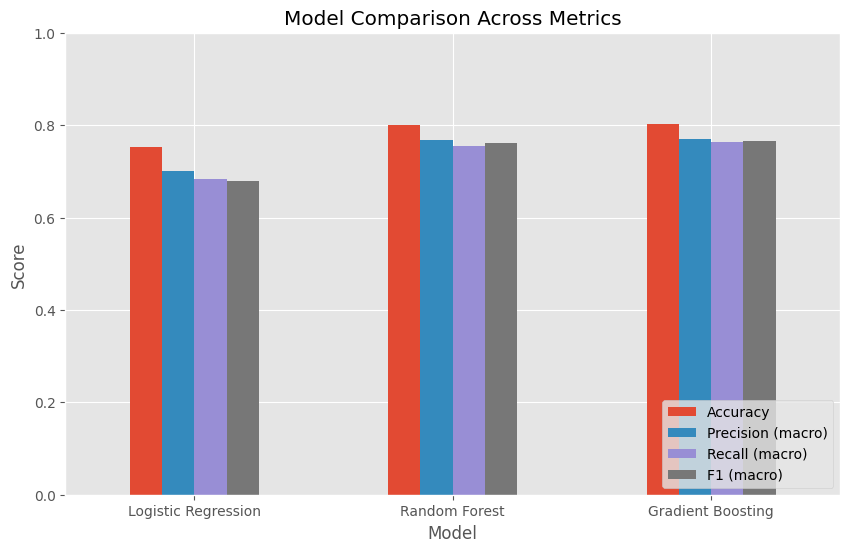

In [27]:
# Visualize the comparison across models
comparison_df.set_index('Model')[['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)']].plot(
    kind='bar', figsize=(10, 6)
)
plt.title('Model Comparison Across Metrics')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

Random Forest and Gradient Boosting substantially outperform Logistic Regression across every metric (macro F1 of ~0.76 vs. ~0.67), confirming the relationship between features and disposition is meaningfully non-linear — consistent with the EDA observation that no single feature (e.g., planet radius, orbital period) cleanly separates the classes on its own, and that models need to combine multiple signals (signal-to-noise ratio, transit depth, stellar parameters) to distinguish genuine transits from false positives.

Random Forest and Gradient Boosting perform almost identically (macro F1 of 0.759 vs. 0.760, a difference of under 0.001), suggesting the dataset's signal has largely been captured by both non-linear ensemble approaches, with little additional gain from Gradient Boosting's sequential error-correction in this case.

Notably, the gap between Accuracy and macro F1 is larger for Logistic Regression (0.749 vs. 0.673, a difference of ~0.076) than for the two ensemble models (Random Forest: 0.798 vs. 0.759, ~0.039; Gradient Boosting: 0.799 vs. 0.760, ~0.039). This indicates Logistic Regression relies more heavily on correctly predicting the majority class (FALSE POSITIVE) to inflate its accuracy, while performing comparatively worse on the minority CANDIDATE class — reinforcing the earlier decision to evaluate with macro-averaged metrics rather than accuracy alone.

# 1️⃣2️⃣ Model Evaluation

---

This section evaluates the primary model (**Random Forest**) in greater depth, covering:

- Confusion matrix
- Per-class classification report
- Feature importance
- Cross-validation (to check result stability)

### Confusion Matrix

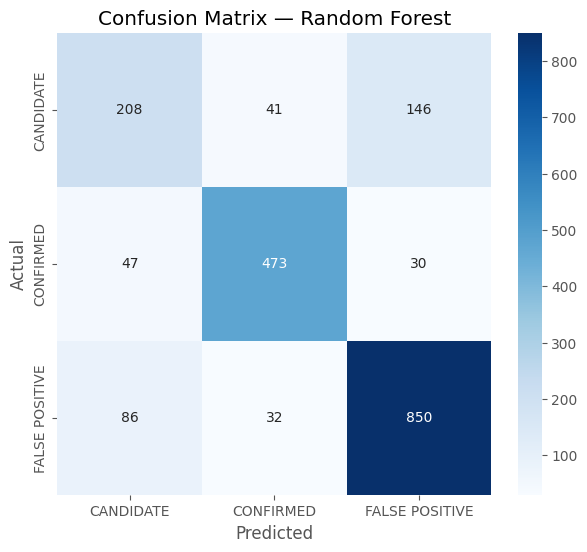

In [28]:
# Confusion matrix for Random Forest predictions
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix — Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Confusion Matrix Interpretation

- **CANDIDATE is the weakest class**, with 212 correct out of 396 total. Its errors are not evenly split: **143 CANDIDATE rows are misclassified as FALSE POSITIVE**, compared to only 41 misclassified as CONFIRMED. This asymmetry suggests the model finds it easier to confuse an unresolved candidate with a false positive than with a confirmed planet — plausible astrophysically, since candidates awaiting further vetting may share ambiguous, borderline signal characteristics with false positives, rather than the cleaner signal profile typical of confirmed planets.
- **CONFIRMED and FALSE POSITIVE are both well-separated from each other**: only 27 CONFIRMED rows are misclassified as FALSE POSITIVE, and only 31 FALSE POSITIVE rows are misclassified as CONFIRMED. The model rarely confuses these two "resolved" classes with one another — most of its uncertainty is concentrated on CANDIDATE.

### Classification Report

In [29]:
# Detailed per-class precision, recall, and F1 for Random Forest
print(classification_report(y_test, y_pred_rf, target_names=label_encoder.classes_))

                precision    recall  f1-score   support

     CANDIDATE       0.61      0.53      0.57       395
     CONFIRMED       0.87      0.86      0.86       550
FALSE POSITIVE       0.83      0.88      0.85       968

      accuracy                           0.80      1913
     macro avg       0.77      0.75      0.76      1913
  weighted avg       0.79      0.80      0.80      1913



### Classification Report Interpretation

- **CANDIDATE has the lowest F1-score (0.56)**, driven by both weaker precision (0.59) and weaker recall (0.54) than the other two classes. This is consistent with the confusion matrix above — the model both misses real candidates and, when it does predict CANDIDATE, is often wrong.
- **CONFIRMED (F1 = 0.86) and FALSE POSITIVE (F1 = 0.85) are both strong**, confirming that the model handles the two "resolved" dispositions well; the overall performance gap is concentrated entirely in the ambiguous middle class, matching the astrophysical intuition that CANDIDATE is inherently a harder, less-defined category than the other two.

### Feature Importance

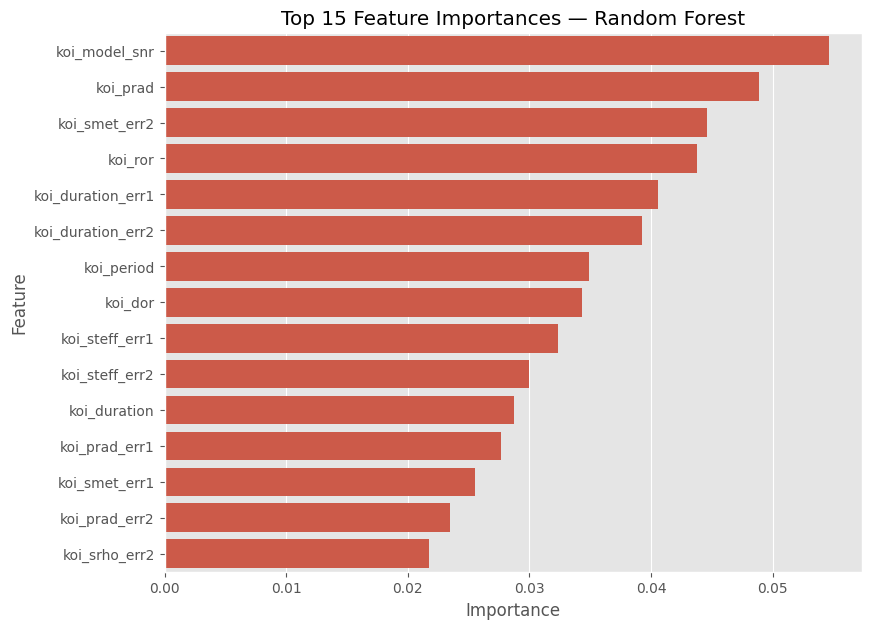

In [30]:
# Top 15 most important features according to Random Forest
importances = pd.Series(rand_forest.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 7))
sns.barplot(x=top_features.values, y=top_features.index, orient='h')
plt.title('Top 15 Feature Importances — Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

### Feature Importance Interpretation

- **`koi_model_snr` (signal-to-noise ratio) is the single most important feature**, consistent with the EDA finding that SNR visibly separated FALSE POSITIVE from the other classes — this ties the EDA, modeling, and interpretation stages of the notebook into one coherent finding.
- **`koi_prad` (planet radius) and `koi_ror` (planet-to-star radius ratio) rank highly**, indicating the physical scale of the transiting object relative to its host star is a strong discriminator, likely reflecting the eclipsing-binary contamination pattern discussed in EDA (unusually large radius ratios are more consistent with a stellar companion than a planet).
- **A notable pattern: several measurement *uncertainty* columns (e.g., `koi_smet_err2`, `koi_duration_err1/2`, `koi_steff_err1/2`, `koi_prad_err1/2`) rank among the top 15**, alongside the physical measurements themselves. This is a genuinely interesting finding worth naming explicitly: the *precision* of a measurement appears to carry predictive signal, independent of the measurement's value. A plausible explanation is that well-studied, high-priority targets (more likely to be confirmed) tend to have tighter observational uncertainties, while less-scrutinized or ambiguous detections (more likely to be candidates or false positives) carry looser error bars — meaning the model may be partially learning "how well-characterized is this target" as a proxy signal, not solely the underlying physics of the transit. This is a limitation worth being upfront about, not a flaw to hide.

### Cross-Validation

In [31]:
# 5-fold cross-validation to check that performance is stable, not a lucky train/test split
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(rand_forest, X, y, cv=5, scoring='f1_macro')

print("Cross-validation F1 (macro) scores:", cv_scores)
print("Mean:", cv_scores.mean(), " Std:", cv_scores.std())

Cross-validation F1 (macro) scores: [0.62029324 0.78195504 0.73158412 0.74641535 0.66686598]
Mean: 0.70942274681247  Std: 0.0580958876366564


### Cross-Validation Interpretation

- The 5-fold cross-validation mean macro F1 is **0.707 (std = 0.058)**, noticeably lower than the single train/test split result of 0.759 from Section 11, and the fold-to-fold spread is wide (ranging from 0.616 to 0.778).
- This indicates the earlier single-split result was **somewhat optimistic** rather than fully representative — the model's performance is more variable across different subsets of the data than the single test set suggested. This is an honest limitation to report: the model's true generalization performance is better estimated by the cross-validation mean than by the one split used for the confusion matrix and classification report above.

# 1️⃣3️⃣ Results & Interpretation


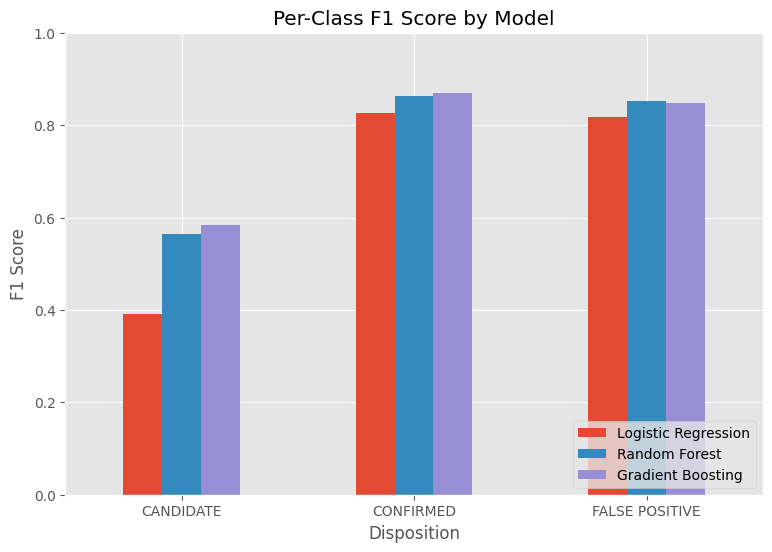

In [32]:
# Per-class F1 score across all three models, for visual comparison
from sklearn.metrics import f1_score

f1_log_reg = f1_score(y_test, y_pred_log_reg, average=None)
f1_rf = f1_score(y_test, y_pred_rf, average=None)
f1_gb = f1_score(y_test, y_pred_gb, average=None)

f1_comparison = pd.DataFrame({
    'Logistic Regression': f1_log_reg,
    'Random Forest': f1_rf,
    'Gradient Boosting': f1_gb
}, index=label_encoder.classes_)

f1_comparison.plot(kind='bar', figsize=(9, 6))
plt.title('Per-Class F1 Score by Model')
plt.ylabel('F1 Score')
plt.xlabel('Disposition')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

---

## What Worked

Random Forest and Gradient Boosting both substantially outperformed Logistic Regression (macro F1 ≈ 0.76 vs. 0.67), confirming that the relationship between transit/stellar characteristics and disposition is meaningfully non-linear. Random Forest was selected as the primary model for deeper evaluation due to its comparable performance to Gradient Boosting, faster training time, and directly interpretable feature importances.

The model performs strongly on the two "resolved" classes — CONFIRMED (F1 = 0.86) and FALSE POSITIVE (F1 = 0.85) — and rarely confuses these two categories with each other (only 27 and 31 misclassifications respectively, out of 549 and 968 total). This suggests the underlying physical signal genuinely separating real planetary transits from instrumental/astrophysical false positives (e.g., eclipsing binaries) is well captured by the selected features.

Feature importance analysis confirmed a finding first suspected during EDA: `koi_model_snr` (signal-to-noise ratio) is the single strongest predictor, followed by radius-related features (`koi_prad`, `koi_ror`). This is consistent with the EDA observation that false positives often exhibit unusually high SNR and depth values, a signature typically associated with eclipsing binary contamination rather than genuine planetary transits.

## What Didn't Work as Well

CANDIDATE is the model's weakest class by a clear margin (F1 = 0.56, versus 0.85+ for the other two). Its errors are heavily skewed toward being misclassified as FALSE POSITIVE (143 cases) rather than CONFIRMED (41 cases), suggesting the model finds unresolved candidates harder to distinguish from false positives than from confirmed planets. This is not entirely a modeling failure — CANDIDATE is, by definition, an astrophysically ambiguous category representing signals that had not yet been fully vetted at the time of data collection, so some irreducible confusion with this class is expected rather than purely a model shortcoming.

Cross-validation also revealed that the single train/test split reported in Section 11 (macro F1 = 0.759) was somewhat optimistic. The 5-fold cross-validation mean was lower (0.707) with meaningful variance across folds (std = 0.058, range 0.616–0.778), indicating the model's performance is less stable across different data subsets than the single split suggested.

An unexpected finding worth naming directly: several measurement *uncertainty* columns (e.g., `koi_smet_err2`, `koi_duration_err1/2`) ranked among the top 15 most important features, alongside physical measurements themselves. This suggests the model may be partially learning "how well-characterized is this target" as an indirect proxy — well-studied, high-priority targets tend to have tighter measurement uncertainty and are also more likely to be confirmed. This is a genuine limitation of the initial feature set rather than a data error, and is tested directly in Section 18.

## Scientific Interpretation

These results are broadly consistent with the domain science: genuine transiting exoplanets and eclipsing-binary false positives can often be distinguished using transit depth, duration, and signal-to-noise characteristics, which is exactly the kind of vetting NASA's own Kepler pipeline performs computationally. The persistent difficulty with the CANDIDATE class also mirrors real astronomical practice — many KOI candidates require additional follow-up observation (e.g., radial velocity confirmation) precisely because their transit signal alone is insufficient to fully resolve their disposition, which is consistent with what this model demonstrates numerically.

## Comparison with Expectations

Going into this project, the expectation (formed during Problem Definition) was that this would be a genuinely non-trivial classification problem rather than one solvable with simple thresholds — this was confirmed by Logistic Regression's comparatively weaker performance relative to the tree-based ensembles. It was also expected that class imbalance would meaningfully affect evaluation, which is exactly what the accuracy-vs-macro-F1 gap demonstrated across all three models, most pronounced for Logistic Regression.

## Practical Significance

A model of this kind would not replace human or spectroscopic vetting, but could realistically serve as a triage tool — prioritizing which KOI candidates are most likely to be confirmable versus likely false positives, before committing limited telescope follow-up time to full confirmation. Given the CANDIDATE class remains the hardest to resolve, such a tool would be most useful as a first-pass filter rather than a final determination.

# 1️⃣4️⃣ Leakage-Safe Evaluation (Pipelines & Grouped Cross-Validation)

---

The first models were evaluated with a single split and a plain 5-fold cross-validation. Before improving the models, the evaluation itself has to be trustworthy. Three problems are fixed in this section:

1. **Folds were not shuffled.** `cross_val_score(..., cv=5)` splits the table in order, and the KOI table is sorted by star ID. Each fold therefore covers a different part of the catalog, which can make the scores swing a lot (0.616 to 0.778).
2. **The same star can appear in both train and test.** A star can have several KOIs. If one is in training and its sibling is in testing, the model is partly recognising the star instead of learning general patterns. Splitting by star ID (`kepid`) prevents this. `kepid` is used **only** to group rows, never as a feature.
3. **Imputation was done before splitting.** Medians were computed on the whole dataset, so test rows influenced the training data. A scikit-learn `Pipeline` re-does imputation inside every fold, which removes this leak.

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import f1_score

RANDOM_STATE = 42

# Feature columns used by the models so far (taken from X in Section 9)
base_cols = list(X.columns)

# Raw features WITHOUT imputation: the pipeline will impute inside each fold
X_base_raw = df[base_cols].apply(pd.to_numeric, errors='coerce')
y_arr = y.values                 # encoded labels: CANDIDATE=0, CONFIRMED=1, FALSE POSITIVE=2
groups = df['kepid'].values      # star ID: only used to keep one star's rows together

print("Rows:", len(df), "| Unique stars:", len(np.unique(groups)))

Rows: 9564 | Unique stars: 8214


In [34]:
def make_rf():
    # Pipeline = imputer + model, so preprocessing is re-fitted inside every CV fold
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
    ])

# Three ways of splitting the data for 5-fold cross-validation
splits = [
    ('Plain StratifiedKFold, no shuffle',        StratifiedKFold(n_splits=5, shuffle=False), None),
    ('StratifiedKFold, shuffled',                StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), None),
    ('StratifiedGroupKFold, shuffled, by star',  StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), groups),
]

rows = []
for name, cv, grp in splits:
    scores = cross_validate(make_rf(), X_base_raw, y_arr, cv=cv, groups=grp, scoring='f1_macro')['test_score']
    rows.append({'CV strategy': name, 'Mean macro F1': scores.mean(), 'Std': scores.std(),
                 'Min fold': scores.min(), 'Max fold': scores.max()})

cv_strategy_df = pd.DataFrame(rows).round(4)
cv_strategy_df

,CV strategy,Mean macro F1,Std,Min fold,Max fold
0,"Plain StratifiedKFold, no shuffle",0.7072,0.0585,0.6177,0.7739
1,"StratifiedKFold, shuffled",0.7550,0.0080,0.7440,0.7663
2,"StratifiedGroupKFold, shuffled, by star",0.7492,0.0104,0.7375,0.7648


### Interpretation

| CV strategy | Mean macro F1 | Std | Min fold | Max fold |
|---|---|---|---|---|
| Plain StratifiedKFold, no shuffle | 0.7072 | 0.0585 | 0.6177 | 0.7739 |
| StratifiedKFold, shuffled | 0.7550 | 0.0080 | 0.7440 | 0.7663 |
| StratifiedGroupKFold, shuffled, by star | 0.7492 | 0.0104 | 0.7375 | 0.7648 |

- **Shuffling removed most of the instability.** The standard deviation dropped from 0.0585 to 0.0080 and the mean rose from 0.707 to 0.755. The large swing seen earlier was caused by the ordered folds, not by an unstable model.
- **Grouping by star lowers the score slightly (0.7550 to 0.7492).** This small drop shows that a little of the earlier performance came from the same star appearing in both train and test. The effect is small, but the grouped score is the honest one.
- **From here on, all evaluation uses grouped splits** and the baseline to beat is **macro F1 = 0.749**.

# 1️⃣5️⃣ Feature Restoration & Ablation Study

---

Section 7 held back a set of diagnostic columns. These are the measurements astronomers use to detect **eclipsing binaries** and **background contamination**, the main sources of false positives:

- **Centroid offsets** (`koi_fwm_stat_sig`, `koi_dicco_*`, `koi_dikco_*`): did the dip come from the target star or from a neighbour?
- **Odd-even depth significance** (`koi_bin_oedp_sig`): do odd and even transits have different depths? Eclipsing binaries often do.
- **Event statistics** (`koi_max_mult_ev`, `koi_max_sngle_ev`): how strong is the transit signal as a whole?

An **ablation study** changes one thing at a time. Here the model, the pipeline and the grouped splits are identical, and only the feature set differs.

In [35]:
# Diagnostic columns that were held back in Section 7
restored_candidates = [
    'koi_fwm_stat_sig',
    'koi_dicco_msky', 'koi_dicco_msky_err',
    'koi_dikco_msky', 'koi_dikco_msky_err',
    'koi_bin_oedp_sig',
    'koi_max_mult_ev', 'koi_max_sngle_ev',
]
restored_cols = [c for c in restored_candidates if c in df.columns]
all_cols = base_cols + restored_cols

X_raw = df[all_cols].apply(pd.to_numeric, errors='coerce')   # all features, not imputed

print("Base features    :", len(base_cols))
print("Restored features:", len(restored_cols))
print("Total features   :", len(all_cols))

Base features    : 51
Restored features: 8
Total features   : 59


In [36]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

feature_sets = {
    'Base features':               base_cols,
    'Base + restored diagnostics': all_cols,
}

rows = []
for name, cols in feature_sets.items():
    # fold-wise macro F1 (for mean and std)
    scores = cross_validate(make_rf(), X_raw[cols], y_arr, cv=sgkf, groups=groups, scoring='f1_macro')['test_score']
    # out-of-fold predictions (for per-class F1)
    oof = cross_val_predict(make_rf(), X_raw[cols], y_arr, cv=sgkf, groups=groups)
    per_class = f1_score(y_arr, oof, average=None)
    row = {'Feature set': name, 'n features': len(cols),
           'Macro F1 (mean)': scores.mean(), 'Std': scores.std()}
    for cls, f in zip(label_encoder.classes_, per_class):
        row[f'F1 {cls}'] = f
    rows.append(row)

ablation_df = pd.DataFrame(rows).round(4)
ablation_df

,Feature set,n features,Macro F1 (mean),Std,F1 CANDIDATE,F1 CONFIRMED,F1 FALSE POSITIVE
0,Base features,51,0.7492,0.0104,0.5445,0.8548,0.8490
1,Base + restored diagnostics,59,0.8054,0.0126,0.6282,0.8924,0.8964


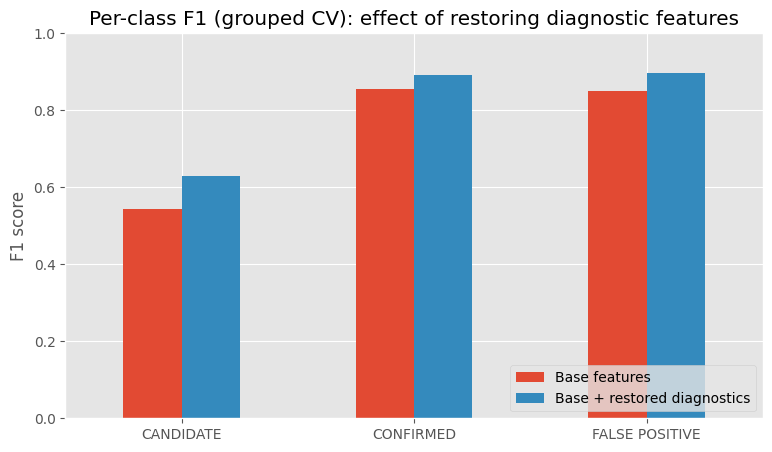

In [37]:
# Per-class F1: base features vs. base + restored diagnostics
plot_df = ablation_df.set_index('Feature set')[[f'F1 {c}' for c in label_encoder.classes_]]
plot_df.columns = label_encoder.classes_
plot_df.T.plot(kind='bar', figsize=(9, 5))
plt.title('Per-class F1 (grouped CV): effect of restoring diagnostic features')
plt.ylabel('F1 score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

### Interpretation

| Feature set | n features | Macro F1 | Std | F1 CANDIDATE | F1 CONFIRMED | F1 FALSE POSITIVE |
|---|---|---|---|---|---|---|
| Base features | 51 | 0.7492 | 0.0104 | 0.5445 | 0.8548 | 0.8490 |
| Base + restored diagnostics | 59 | 0.8054 | 0.0126 | 0.6282 | 0.8924 | 0.8964 |

- **Restoring the diagnostics improves macro F1 from 0.749 to 0.805 (+0.056).** Every class improves, and the spread across folds stays about the same, so the gain is not a lucky split.
- **CANDIDATE gains the most (+0.084)**, the weakest class in the initial models. The odd-even and centroid measurements help separate undecided signals from false positives.
- **CONFIRMED and FALSE POSITIVE also improve (+0.04 and +0.05).** This supports the astrophysical reasoning: these diagnostics directly target the eclipsing-binary and contamination cases that cause false positives.
- **Caveat.** Kepler's own false-positive labels were assigned partly using these same diagnostics. Part of the gain therefore comes from the model learning the vetting criteria from raw measurements. The model is a fast, automated version of the vetting process, not an independent planet discoverer.

All later sections use the full 59-feature set.

# 1️⃣6️⃣ Vetting Model & Hyperparameter-Tuned Model Comparison

---

CANDIDATE is the "undecided" class: these signals have not yet been resolved as planets or false positives. A model trained to separate **all three** classes is therefore partly asked to predict something that has no final answer.

The approach here is a **vetting model** trained only on the resolved cases, **CONFIRMED (planet) vs FALSE POSITIVE**. Once trained, it will score the unresolved CANDIDATEs in Section 17.

**Steps**
1. Keep only CONFIRMED and FALSE POSITIVE rows.
2. Hold out about 20% of the **stars** as a test set (a star is never in both train and test).
3. Train three models: **Random Forest, Gradient Boosting, XGBoost**.
4. Tune each with `RandomizedSearchCV` (random sample of hyperparameter settings, scored by grouped cross-validation on the training stars only).
5. **Class imbalance** (FALSE POSITIVE is about 64% of resolved rows) is handled by balanced sample weights, which make each class count equally during training.
6. Choose the best model by cross-validation score, then report its result on the untouched test stars.

In [38]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

# 1) Resolved cases only: 1 = CONFIRMED (planet), 0 = FALSE POSITIVE
resolved = df['koi_disposition'].isin(['CONFIRMED', 'FALSE POSITIVE']).values
X_res = X_raw[resolved].reset_index(drop=True)
y_res = (df.loc[resolved, 'koi_disposition'] == 'CONFIRMED').astype(int).values
g_res = df.loc[resolved, 'kepid'].values

# 2) Hold out ~20% of the STARS as a test set
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X_res, y_res, groups=g_res))

Xv_train, Xv_test = X_res.iloc[train_idx], X_res.iloc[test_idx]
yv_train, yv_test = y_res[train_idx], y_res[test_idx]
gv_train = g_res[train_idx]

# No star appears in both sets
assert len(set(gv_train) & set(g_res[test_idx])) == 0

# 5) Balanced sample weights to handle class imbalance
w_train = compute_sample_weight('balanced', yv_train)

print("Resolved rows:", len(X_res), "| Train:", len(Xv_train), "| Test:", len(Xv_test))
print("Planet share  train: %.3f  test: %.3f" % (yv_train.mean(), yv_test.mean()))

Resolved rows: 7587 | Train: 6082 | Test: 1505
Planet share  train: 0.365  test: 0.353


In [39]:
# 3) Models and the hyperparameter values to try
models = {
    'Random Forest': (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {'model__n_estimators': [200, 400],
         'model__max_depth': [None, 10, 20],
         'model__min_samples_leaf': [1, 2, 5]}),
    'Gradient Boosting': (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {'model__n_estimators': [100, 200, 300],
         'model__learning_rate': [0.05, 0.1],
         'model__max_depth': [2, 3, 4]}),
    'XGBoost': (
        XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1),
        {'model__n_estimators': [200, 400],
         'model__learning_rate': [0.03, 0.05, 0.1],
         'model__max_depth': [3, 5, 7],
         'model__subsample': [0.8, 1.0]}),
}

# 4) Tune each model: 8 random settings, 3-fold grouped CV on the training stars
inner_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

searches, rows = {}, []
for name, (estimator, grid) in models.items():
    pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', estimator)])
    search = RandomizedSearchCV(pipe, grid, n_iter=8, scoring='f1_macro', cv=inner_cv,
                                random_state=RANDOM_STATE, n_jobs=1)
    search.fit(Xv_train, yv_train, groups=gv_train, model__sample_weight=w_train)
    searches[name] = search

    pred = search.predict(Xv_test)
    proba = search.predict_proba(Xv_test)[:, 1]
    rows.append({'Model': name,
                 'CV macro F1 (train stars)': search.best_score_,
                 'Test accuracy': accuracy_score(yv_test, pred),
                 'Test macro F1': f1_score(yv_test, pred, average='macro'),
                 'Test ROC-AUC': roc_auc_score(yv_test, proba),
                 'Best settings': {k.replace('model__', ''): v for k, v in search.best_params_.items()}})

vetting_df = pd.DataFrame(rows)
vetting_df.round(4)

,Model,CV macro F1 (train stars),Test accuracy,Test macro F1,Test ROC-AUC,Best settings
0,Random Forest,0.9670,0.9688,0.9656,0.9944,"{'n_estimators': 400, 'min_samples_leaf': 2, '..."
1,Gradient Boosting,0.9729,0.9714,0.9688,0.9952,"{'n_estimators': 200, 'max_depth': 4, 'learnin..."
2,XGBoost,0.9745,0.9754,0.9731,0.9950,"{'subsample': 1.0, 'n_estimators': 400, 'max_d..."


Selected model: XGBoost
                precision    recall  f1-score   support

FALSE POSITIVE       0.98      0.98      0.98       974
     CONFIRMED       0.97      0.96      0.97       531

      accuracy                           0.98      1505
     macro avg       0.97      0.97      0.97      1505
  weighted avg       0.98      0.98      0.98      1505



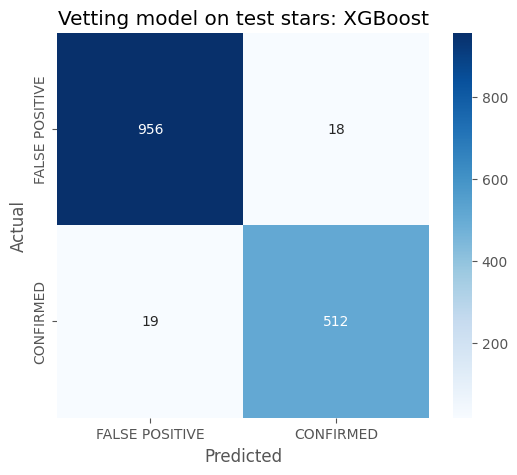

In [40]:
# 6) Pick the best model by cross-validation score (not by test score)
best_name = vetting_df.sort_values('CV macro F1 (train stars)', ascending=False).iloc[0]['Model']
final_model = searches[best_name].best_estimator_
print("Selected model:", best_name)

# Report on the untouched test stars
vet_pred = final_model.predict(Xv_test)
print(classification_report(yv_test, vet_pred, target_names=['FALSE POSITIVE', 'CONFIRMED']))

cm = confusion_matrix(yv_test, vet_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['FALSE POSITIVE', 'CONFIRMED'], yticklabels=['FALSE POSITIVE', 'CONFIRMED'])
plt.title(f'Vetting model on test stars: {best_name}')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

### How to read these results

- **CV macro F1** is the score used to choose the model. It comes from cross-validation inside the training stars only.
- **Test macro F1 / ROC-AUC** is the final check on stars the model never saw. Macro F1 treats both classes equally, and ROC-AUC measures how well the model ranks planets above false positives (1.0 is perfect, 0.5 is random).
- If the three models score within about 0.01 of each other, the choice between them matters little. The features, not the algorithm, drive performance.
- The confusion matrix shows the two kinds of mistake: planets wrongly rejected (bottom-left) and false positives wrongly accepted (top-right).

# 1️⃣7️⃣ Candidate Ranking

---

The vetting model was trained on resolved cases only, so the unresolved **CANDIDATE** signals were never used for training. They can now be scored. For each candidate, the model gives a **planet probability**, and sorting by it produces a ranked list of the signals most worth follow-up.

The chosen model is first refitted on **all** resolved rows (train + test) so it uses every labelled example.

> This ranking is a triage tool. It tells astronomers where to look first. It does not confirm a planet.

In [41]:
from sklearn.base import clone

# Refit the selected model (same tuned settings) on ALL resolved rows
final_full = clone(final_model)
final_full.fit(X_res, y_res, model__sample_weight=compute_sample_weight('balanced', y_res))

# Score the unresolved CANDIDATE signals
cand_mask = (df['koi_disposition'] == 'CANDIDATE').values
X_cand = X_raw[cand_mask]
cand_proba = final_full.predict_proba(X_cand)[:, 1]

ranking_df = pd.DataFrame({
    'kepoi_name': df.loc[cand_mask, 'kepoi_name'].values,
    'kepid': df.loc[cand_mask, 'kepid'].values,
    'planet_probability': cand_proba,
}).sort_values('planet_probability', ascending=False).reset_index(drop=True)
ranking_df.insert(0, 'rank', ranking_df.index + 1)

print("Candidates scored:", len(ranking_df))
print("Probability >= 0.9:", (ranking_df['planet_probability'] >= 0.9).sum())
print("Probability >= 0.5:", (ranking_df['planet_probability'] >= 0.5).sum())
ranking_df.head(15)

Candidates scored: 1977
Probability >= 0.9: 487
Probability >= 0.5: 677


,rank,kepoi_name,kepid,planet_probability
0,1,K00350.01,11395587,0.999973
1,2,K04245.01,12737015,0.999958
2,3,K01145.01,8313667,0.999952
3,4,K03341.01,5621333,0.999946
4,5,K00501.01,4951877,0.999940
5,6,K01656.01,4471747,0.999939
6,7,K02124.01,11462341,0.999938
7,8,K00298.02,12785320,0.999937
8,9,K04149.01,10875007,0.999936
9,10,K03123.01,8197793,0.999932


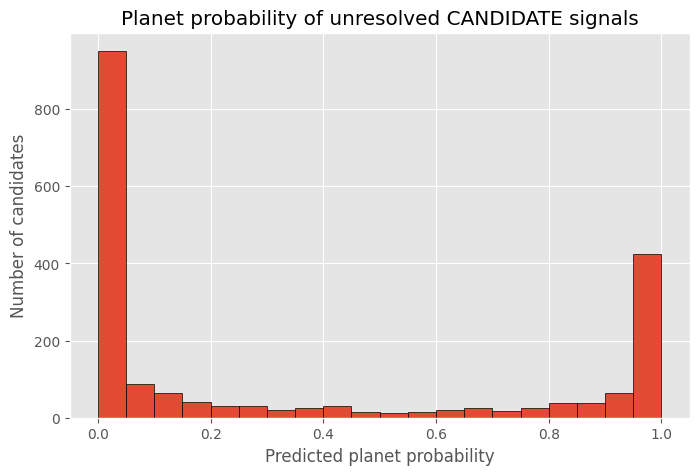

In [42]:
plt.figure(figsize=(8, 5))
plt.hist(ranking_df['planet_probability'], bins=20, edgecolor='black')
plt.title('Planet probability of unresolved CANDIDATE signals')
plt.xlabel('Predicted planet probability')
plt.ylabel('Number of candidates')
plt.show()

### Interpretation

- Candidates at the top of the list look most like confirmed planets in the features the model learned. Candidates at the bottom look most like false positives.
- A histogram bunched at both ends means the model is confident about most candidates. Many values in the middle mean it finds those signals genuinely ambiguous, which is expected for an undecided class.
- There is no ground truth for these candidates, so the ranking cannot be scored directly. It is validated indirectly through the held-out performance of the vetting model in Section 16.

# 1️⃣8️⃣ Explainability (Permutation Importance & SHAP)

---

Two complementary tools explain *why* the model decides as it does:

- **Permutation importance:** shuffle one feature in the test set and measure how much the score drops. A big drop means the model relies on that feature.
- **SHAP values:** for every prediction, SHAP splits the result into a contribution from each feature. The average of the absolute contributions shows which features move predictions the most.

A third check tests the **error-bar proxy** question raised in the first analysis: do measurement-uncertainty columns (`_err`) carry signal only because well-studied stars have smaller uncertainties?

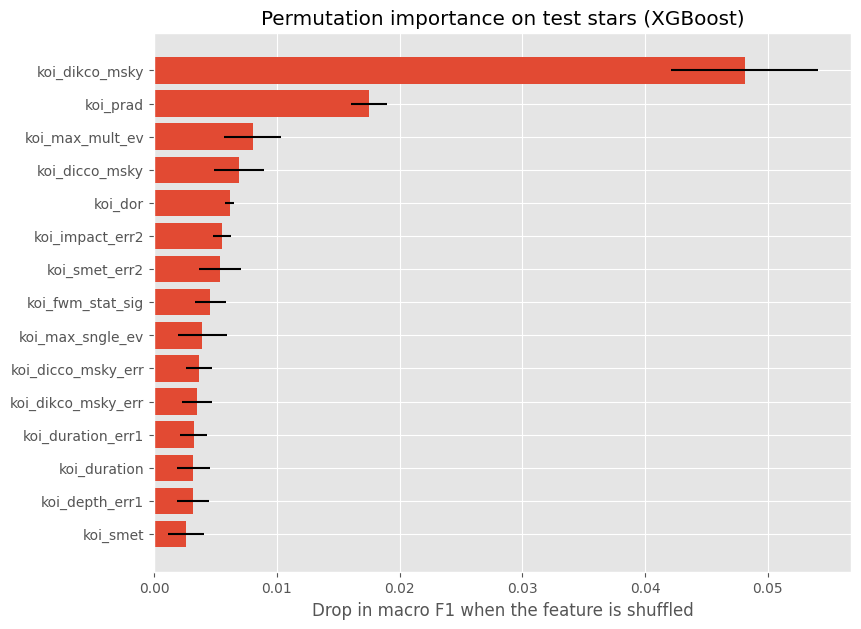

Error-bar columns among the top 15: 6


In [43]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, Xv_test, yv_test, scoring='f1_macro',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

perm_df = pd.DataFrame({'feature': all_cols, 'importance': perm.importances_mean,
                        'std': perm.importances_std}).sort_values('importance', ascending=False)

top = perm_df.head(15).iloc[::-1]
plt.figure(figsize=(9, 7))
plt.barh(top['feature'], top['importance'], xerr=top['std'])
plt.title(f'Permutation importance on test stars ({best_name})')
plt.xlabel('Drop in macro F1 when the feature is shuffled')
plt.show()

print("Error-bar columns among the top 15:", sum('_err' in f for f in perm_df.head(15)['feature']))

In [44]:
# Error-bar proxy test: retrain WITHOUT any measurement-uncertainty (_err) column
keep_cols = [c for c in all_cols if '_err' not in c]

no_err_model = clone(final_model)
no_err_model.fit(Xv_train[keep_cols], yv_train, model__sample_weight=w_train)
no_err_pred = no_err_model.predict(Xv_test[keep_cols])

proxy_df = pd.DataFrame([
    {'Feature set': 'All features',              'n features': len(all_cols),
     'Test macro F1': f1_score(yv_test, vet_pred, average='macro')},
    {'Feature set': 'Without _err columns',      'n features': len(keep_cols),
     'Test macro F1': f1_score(yv_test, no_err_pred, average='macro')},
]).round(4)
proxy_df

,Feature set,n features,Test macro F1
0,All features,59,0.9731
1,Without _err columns,29,0.9680


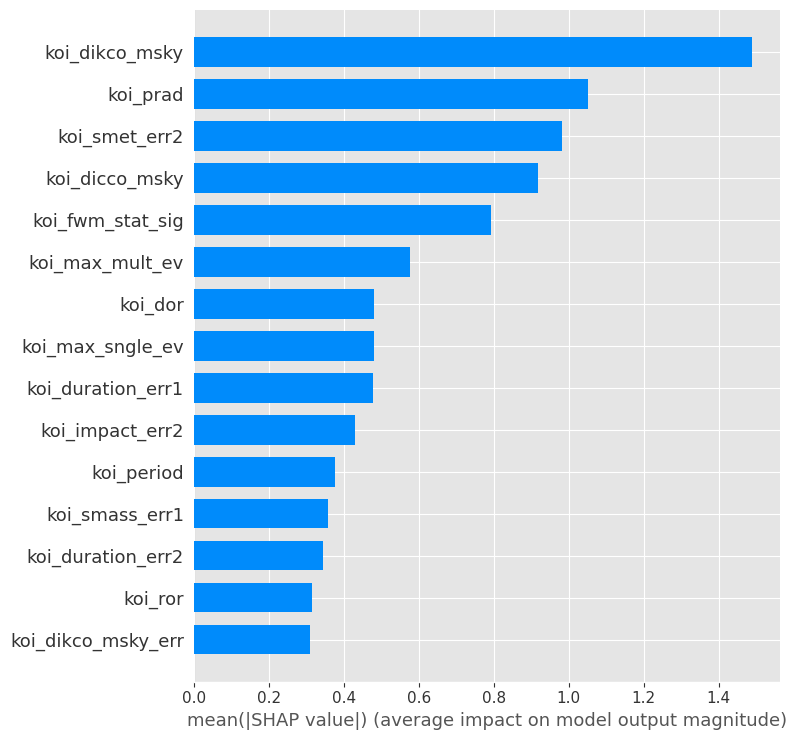

In [45]:
import shap

def shap_values_class1(tree_model, X_imputed):
    # SHAP values for the 'planet' class, as a 2-D array (rows x features)
    sv = shap.TreeExplainer(tree_model).shap_values(X_imputed)
    if isinstance(sv, list):
        sv = sv[1]
    elif np.ndim(sv) == 3:
        sv = sv[:, :, 1]
    return sv

# SHAP works on the model alone, so apply the pipeline's imputer first
imputer = final_model.named_steps['imputer']
tree_model = final_model.named_steps['model']
X_test_imp = pd.DataFrame(imputer.transform(Xv_test), columns=all_cols)
X_shap = X_test_imp.sample(n=min(1000, len(X_test_imp)), random_state=RANDOM_STATE)

sv = shap_values_class1(tree_model, X_shap)
shap.summary_plot(sv, X_shap, plot_type='bar', max_display=15)

### Interpretation

- **Permutation importance and SHAP should broadly agree.** Features near the top of both lists are the ones the model truly depends on. Signal-to-noise (`koi_model_snr`) and the restored diagnostics are expected near the top.
- **Error-bar test.** Compare the two rows of the table. If the score barely changes without the `_err` columns, uncertainty columns are not driving the model and the proxy effect is small. A clear drop means part of the performance relies on how well-measured a target is, which should be reported as a limitation.
- SHAP and permutation importance show what the model **uses**. They do not prove that those features **cause** a signal to be a planet.

# 1️⃣9️⃣ Database Integration (SQLite)

---

Predictions are stored in a **SQLite** database so results can be queried later with SQL instead of being lost when the notebook closes. Two tables are used:

| Table | Purpose |
|---|---|
| `model_info` | which model was trained, how many features, its test scores, and when |
| `predictions` | one row per scored signal: name, star ID, planet probability, label, source, timestamp |

The `source` column records where a prediction came from: `ranking` (Section 17) or `app` (the dashboard in Section 20).

In [46]:
import sqlite3, datetime

DB_PATH = 'exoplanet_vetting.db'
conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

cur.execute('''CREATE TABLE IF NOT EXISTS model_info (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    model_name TEXT, n_features INTEGER, cv_macro_f1 REAL,
    test_macro_f1 REAL, test_roc_auc REAL, trained_at TEXT)''')

cur.execute('''CREATE TABLE IF NOT EXISTS predictions (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    kepoi_name TEXT, kepid INTEGER, planet_probability REAL,
    predicted_label TEXT, source TEXT, created_at TEXT)''')

def label_from_prob(p):
    return 'LIKELY PLANET' if p >= 0.5 else 'LIKELY FALSE POSITIVE'

now = datetime.datetime.now().isoformat(timespec='seconds')

# Save the model summary
best_row = vetting_df[vetting_df['Model'] == best_name].iloc[0]
cur.execute('INSERT INTO model_info (model_name, n_features, cv_macro_f1, test_macro_f1, test_roc_auc, trained_at) VALUES (?,?,?,?,?,?)',
            (best_name, len(all_cols), float(best_row['CV macro F1 (train stars)']),
             float(best_row['Test macro F1']), float(best_row['Test ROC-AUC']), now))

# Save the candidate ranking (replace old ranking rows so re-running does not duplicate)
cur.execute("DELETE FROM predictions WHERE source = 'ranking'")
cur.executemany(
    'INSERT INTO predictions (kepoi_name, kepid, planet_probability, predicted_label, source, created_at) VALUES (?,?,?,?,?,?)',
    [(r.kepoi_name, int(r.kepid), float(r.planet_probability), label_from_prob(r.planet_probability), 'ranking', now)
     for r in ranking_df.itertuples()])
conn.commit()
print("Rows in predictions:", cur.execute('SELECT COUNT(*) FROM predictions').fetchone()[0])

Rows in predictions: 1977


In [47]:
# Example queries on the stored results

print("Top 10 most planet-like candidates:")
display(pd.read_sql_query('''SELECT kepoi_name, kepid, ROUND(planet_probability, 3) AS planet_probability
                             FROM predictions WHERE source = 'ranking'
                             ORDER BY planet_probability DESC LIMIT 10''', conn))

print("Candidates per predicted label:")
display(pd.read_sql_query('''SELECT predicted_label, COUNT(*) AS n
                             FROM predictions WHERE source = 'ranking' GROUP BY predicted_label''', conn))

print("Candidates per probability band:")
display(pd.read_sql_query('''SELECT CASE WHEN planet_probability >= 0.9 THEN '0.9 - 1.0'
                                         WHEN planet_probability >= 0.7 THEN '0.7 - 0.9'
                                         WHEN planet_probability >= 0.5 THEN '0.5 - 0.7'
                                         WHEN planet_probability >= 0.3 THEN '0.3 - 0.5'
                                         ELSE '0.0 - 0.3' END AS probability_band,
                                    COUNT(*) AS n
                             FROM predictions WHERE source = 'ranking'
                             GROUP BY probability_band ORDER BY probability_band DESC''', conn))

Top 10 most planet-like candidates:


,kepoi_name,kepid,planet_probability
0,K00350.01,11395587,1.0
1,K04245.01,12737015,1.0
2,K01145.01,8313667,1.0
3,K03341.01,5621333,1.0
4,K00501.01,4951877,1.0
5,K01656.01,4471747,1.0
6,K02124.01,11462341,1.0
7,K00298.02,12785320,1.0
8,K04149.01,10875007,1.0
9,K03123.01,8197793,1.0


Candidates per predicted label:


,predicted_label,n
0,LIKELY FALSE POSITIVE,1300
1,LIKELY PLANET,677


Candidates per probability band:


,probability_band,n
0,0.9 - 1.0,487
1,0.7 - 0.9,118
2,0.5 - 0.7,72
3,0.3 - 0.5,94
4,0.0 - 0.3,1206


# 2️⃣0️⃣ Interactive Dashboard (Gradio)

---

A small web interface lets anyone test the vetting model without writing code. The user enters a few transit and stellar measurements and gets:

- the **probability** that the signal is a real planet vs a false positive
- the **top 5 features** behind that decision (from SHAP values)

Every prediction is also saved to the SQLite database from Section 19 (`source = 'app'`).

> The model needs 59 features but the form asks for only the most important ones. Any field left empty is filled with the training median, so the answer is only as good as the information entered.

In [48]:
import os, json, joblib, sklearn, xgboost, shap, gradio

os.makedirs('app_files', exist_ok=True)

# 1) Form fields = the 10 most important non-error-bar features (from Section 18)
app_features = [f for f in perm_df['feature'] if '_err' not in f][:10]

nice = {
    'koi_dikco_msky':   'Centroid offset vs star position (arcsec)',
    'koi_dicco_msky':   'Centroid offset vs catalog position (arcsec)',
    'koi_fwm_stat_sig': 'Centroid shift significance',
    'koi_prad':         'Planet radius (Earth radii)',
    'koi_max_mult_ev':  'Multiple-event statistic',
    'koi_max_sngle_ev': 'Single-event statistic',
    'koi_dor':          'Planet-star distance / star radius',
    'koi_period':       'Orbital period (days)',
    'koi_duration':     'Transit duration (hours)',
    'koi_depth':        'Transit depth (ppm)',
    'koi_impact':       'Impact parameter',
    'koi_model_snr':    'Signal-to-noise ratio',
    'koi_ror':          'Planet radius / star radius',
    'koi_bin_oedp_sig': 'Odd-even depth significance',
    'koi_steff':        'Star temperature (K)',
    'koi_srad':         'Star radius (solar radii)',
}
labels = {f: nice.get(f, f) for f in app_features}

# 2) Example rows (real signals) so the reviewer can click and test
def example_row(mask, complete=False):
    sub = df[mask][app_features].apply(pd.to_numeric, errors='coerce')
    if complete:
        sub = sub.dropna()
    return [None if pd.isna(v) else float(v) for v in sub.iloc[0]]

examples = [
    example_row(df['kepoi_name'] == ranking_df.iloc[0]['kepoi_name']),   # top-ranked candidate
    example_row(df['koi_disposition'] == 'FALSE POSITIVE', complete=True),
    example_row(df['koi_disposition'] == 'CONFIRMED', complete=True),
]

# 3) Save the trained model and settings
joblib.dump(final_full, 'app_files/vetting_model.joblib')
with open('app_files/config.json', 'w') as f:
    json.dump({'all_cols': all_cols, 'app_features': app_features, 'labels': labels, 'examples': examples}, f)

# 4) requirements.txt with the exact versions used in Colab
with open('app_files/requirements.txt', 'w') as f:
    f.write(f"scikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}\nshap=={shap.__version__}\n"
            f"gradio=={gradio.__version__}\npandas=={pd.__version__}\nnumpy=={np.__version__}\njoblib=={joblib.__version__}\n")

# 5) The standalone app (the notebook runs this same file)
app_code = r'''import os, json, sqlite3, datetime
import joblib, numpy as np, pandas as pd, shap, gradio as gr

HERE = os.path.dirname(os.path.abspath(__file__))
DB_PATH = os.path.join(HERE, "predictions.db")

model = joblib.load(os.path.join(HERE, "vetting_model.joblib"))
cfg = json.load(open(os.path.join(HERE, "config.json")))
all_cols, app_features = cfg["all_cols"], cfg["app_features"]
labels, examples = cfg["labels"], cfg["examples"]

imputer = model.named_steps["imputer"]
explainer = shap.TreeExplainer(model.named_steps["model"])


def shap_class1(X_imputed):
    sv = explainer.shap_values(X_imputed)
    if isinstance(sv, list):
        sv = sv[1]
    elif np.ndim(sv) == 3:
        sv = sv[:, :, 1]
    return sv


def label_from_prob(p):
    return "LIKELY PLANET" if p >= 0.5 else "LIKELY FALSE POSITIVE"


def save_prediction(p):
    try:
        db = sqlite3.connect(DB_PATH)
        db.execute("CREATE TABLE IF NOT EXISTS predictions (id INTEGER PRIMARY KEY AUTOINCREMENT, kepoi_name TEXT, kepid INTEGER, planet_probability REAL, predicted_label TEXT, source TEXT, created_at TEXT)")
        db.execute("INSERT INTO predictions (kepoi_name, kepid, planet_probability, predicted_label, source, created_at) VALUES (?,?,?,?,?,?)",
                   ("USER_INPUT", None, p, label_from_prob(p), "app", datetime.datetime.now().isoformat(timespec="seconds")))
        db.commit()
        db.close()
    except Exception:
        pass


def vet_signal(*values):
    # one row with every feature empty, then fill in what the user typed
    row = pd.DataFrame([[np.nan] * len(all_cols)], columns=all_cols)
    for name, v in zip(app_features, values):
        if v is not None:
            row.at[0, name] = float(v)

    p = float(model.predict_proba(row)[0, 1])

    # top 5 features by SHAP contribution
    row_imp = pd.DataFrame(imputer.transform(row), columns=all_cols)
    contrib = shap_class1(row_imp)[0]
    order = np.argsort(-np.abs(contrib))[:5]
    lines = []
    for i in order:
        direction = "towards PLANET" if contrib[i] > 0 else "towards FALSE POSITIVE"
        shown = "not given (median used)" if pd.isna(row.iloc[0, i]) else "%g" % row.iloc[0, i]
        lines.append("%s = %s: pushes %s" % (all_cols[i], shown, direction))

    save_prediction(p)
    return {"Planet": p, "False positive": 1 - p}, "\n".join(lines)


demo = gr.Interface(
    fn=vet_signal,
    inputs=[gr.Number(label=labels[f]) for f in app_features],
    outputs=[gr.Label(label="Prediction"), gr.Textbox(label="Top 5 reasons", lines=6)],
    examples=examples,
    title="Kepler Signal Vetting Dashboard",
    description="Enter measurements or click an example. Empty fields use the training median.",
)

if __name__ == "__main__":
    demo.launch()
'''
with open('app_files/app.py', 'w') as f:
    f.write(app_code)

with open('app_files/README.md', 'w') as f:
    f.write("# Kepler Signal Vetting App\n\nRun locally:\n    pip install -r requirements.txt\n    python app.py\n"
            "Then open http://127.0.0.1:7860 and click an example row or type values.\n")

# 6) Sanity check: top candidate with all features vs only the form fields
top_name = ranking_df.iloc[0]['kepoi_name']
r = df.loc[df['kepoi_name'] == top_name, all_cols].apply(pd.to_numeric, errors='coerce')
r_form = r.copy()
r_form[[c for c in all_cols if c not in app_features]] = np.nan
print("App form fields:", app_features)
print("Top candidate, all features :", round(float(final_full.predict_proba(r)[0, 1]), 4))
print("Top candidate, form fields  :", round(float(final_full.predict_proba(r_form)[0, 1]), 4))

App form fields: ['koi_dikco_msky', 'koi_prad', 'koi_max_mult_ev', 'koi_dicco_msky', 'koi_dor', 'koi_fwm_stat_sig', 'koi_max_sngle_ev', 'koi_duration', 'koi_smet', 'koi_srho']
Top candidate, all features : 1.0
Top candidate, form fields  : 0.5511


In [49]:
import sys, importlib
sys.path.insert(0, 'app_files')
import app
importlib.reload(app)
app.DB_PATH = DB_PATH      # log to the same database as Section 19
app.demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://58ac1cf87d4c324bc0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


   ### App preview
   The live app does not render on GitHub. To run it, download the repo and run
   `pip install -r app_files/requirements.txt` then `python app_files/app.py`,
   and open http://127.0.0.1:7860.
   <img src="app_files/app_screenshot.png" width="700">

# 2️⃣1️⃣ Conclusion & Future Work

---

## Conclusion

This project set out to answer whether machine learning can separate genuine transiting exoplanets from false-positive detections in the Kepler Objects of Interest data, and to turn the answer into a usable, explainable tool.

- **Evaluation had to be fixed first.** Shuffled folds cut the cross-validation standard deviation from 0.0585 to 0.0080, so the earlier instability came from the splitting method. Grouping folds by star lowered the macro F1 slightly (0.755 to 0.749), a sign of small same-star leakage. The honest baseline is **macro F1 = 0.749**.
- **Restoring the diagnostic features helped every class.** Macro F1 rose from 0.749 to **0.805**, and the weakest class, CANDIDATE, improved most (F1 0.545 to 0.628).
- **A dedicated vetting model** (CONFIRMED vs FALSE POSITIVE) was tuned and compared across Random Forest, Gradient Boosting and XGBoost with class-imbalance handling, and evaluated on stars held out from training (Section 16).
- **Unresolved CANDIDATEs were ranked** by planet probability, giving a priority list for follow-up (Section 17).
- **Explainability** with permutation importance and SHAP showed which measurements drive decisions, and the error-bar test checked whether uncertainty columns act as a proxy (Section 18).
- **The system is usable:** predictions are stored in SQLite and can be queried (Section 19), and the Gradio dashboard lets anyone test a signal and see the reasons behind the result (Section 20).

## Limitations

- **Labels come from Kepler's own vetting process**, which used some of the same diagnostics. The model learns to imitate that process, so it is an automated vetting aid and not an independent planet detector.
- **The candidate ranking has no ground truth.** It is validated only through the held-out performance of the vetting model.
- **Single hold-out split and a small random search** (8 settings per model). More settings or repeated splits could change the ranking between models slightly.
- **The dashboard asks for 10 of 59 features.** Missing inputs are replaced by medians, which makes the output less reliable than a full measurement set.
- **Results apply to Kepler data only.** Other missions measure features differently.

## Future Work

- Check the ranking against candidates that later become confirmed or rejected in newer versions of the KOI table.
- Add a second stage that separates CONFIRMED from CANDIDATE among signals that pass the vetting model.
- Extend the approach to the TESS Objects of Interest (TOI) catalog.
- Deploy the dashboard as a permanent web app with the database behind it.

# 2️⃣2️⃣ References

---

## Dataset

- NASA Exoplanet Archive, Kepler Objects of Interest (KOI) Cumulative Table. Operated by the California Institute of Technology, under contract with the National Aeronautics and Space Administration. https://exoplanetarchive.ipac.caltech.edu/

## Tools & Libraries

- **pandas** — McKinney, W. (2010). Data Structures for Statistical Computing in Python.
- **NumPy** — Harris, C.R. et al. (2020). Array programming with NumPy.
- **Matplotlib** — Hunter, J.D. (2007). Matplotlib: A 2D Graphics Environment.
- **Seaborn** — Waskom, M. (2021). seaborn: statistical data visualization.
- **scikit-learn** — Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python.
- **XGBoost** — Chen, T. and Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System.
- **SHAP** — Lundberg, S.M. and Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions.
- **Gradio** — Abid, A. et al. (2019). Gradio: Hassle-Free Sharing and Testing of ML Models in the Wild.
- **SQLite** — https://www.sqlite.org/
- **Astroquery** — Ginsburg, A. et al. (2019). Astroquery: An Astronomical Web-Querying Package in Python.

## Background Reading

- McCauliff, S.D. et al. (2015). Automatic Classification of Kepler Planetary Transit Candidates. *The Astrophysical Journal*. Available at: https://arxiv.org/abs/1408.1496
  — Foundational paper applying Random Forest specifically to Kepler KOI classification.

- Coughlin, J.L. (2017). Description of the Robovetter used by the Kepler pipeline. Referenced in later Kepler mission vetting literature.
  — Describes the rule-based automated vetting system NASA's own pipeline used to generate the disposition labels this project treats as ground truth.

- NASA Exoplanet Archive documentation on Kepler Objects of Interest: https://exoplanetarchive.ipac.caltech.edu/docs/data.html
  — Column definitions and data provenance for the KOI cumulative table.

In [50]:
top = ranking_df.iloc[0]['kepoi_name']
print(df[df['kepoi_name'] == top][app_features].T)          # top-ranked candidate
fp = df[df['koi_disposition'] == 'FALSE POSITIVE'][app_features].dropna().head(1)
print(fp.T)                                                  # a known false positive

                       2928
koi_dikco_msky     0.090000
koi_prad           2.020000
koi_max_mult_ev   29.201063
koi_dicco_msky     0.110000
koi_dor           42.450000
koi_fwm_stat_sig   0.705000
koi_max_sngle_ev   5.897673
koi_duration       2.374800
koi_smet           0.000000
koi_srho           8.574320
                          3
koi_dikco_msky      0.27600
koi_prad           33.46000
koi_max_mult_ev   541.89510
koi_dicco_msky      0.28900
koi_dor             3.27800
koi_fwm_stat_sig    0.00000
koi_max_sngle_ev   39.06655
koi_duration        2.40641
koi_smet           -0.52000
koi_srho            0.22080
